In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, Model
from sklearn.model_selection import train_test_split
from skimage.metrics import structural_similarity as ssim

np.random.seed(42)
tf.random.set_seed(42)

(x_train, _), (x_test, _) = tf.keras.datasets.mnist.load_data()

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

x_train = x_train[..., np.newaxis]
x_test = x_test[..., np.newaxis]

x_train, x_val = train_test_split(
    x_train,
    test_size=0.1,
    random_state=42
)

print("Training:", x_train.shape)
print("Validation:", x_val.shape)
print("Test:", x_test.shape)
print("Pixel range:", x_train.min(), x_train.max())

import os

FIGURES_DIR = "Figures"
os.makedirs(FIGURES_DIR, exist_ok=True)

def save_fig(name):
    plt.savefig(
        os.path.join(FIGURES_DIR, f"{name}.png"),
        dpi=600,
        bbox_inches="tight"
    )

def save_figure(fig, name):
    fig.savefig(
        os.path.join(FIGURES_DIR, f"{name}.png"),
        dpi=600,
        bbox_inches="tight"
    )


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Training: (54000, 28, 28, 1)
Validation: (6000, 28, 28, 1)
Test: (10000, 28, 28, 1)
Pixel range: 0.0 1.0


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

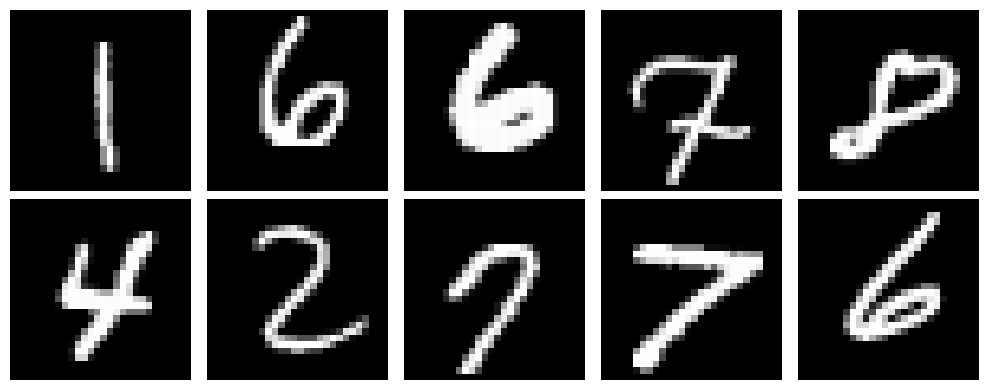

In [2]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for ax, image in zip(axes.ravel(), x_train[:10]):
    ax.imshow(image.squeeze(), cmap="gray")
    ax.axis("off")

plt.tight_layout()
save_figure(fig, "00_Dataset_Sample_Images")
plt.show()

In [3]:
x_train_flat = x_train.reshape(len(x_train), 784)
x_val_flat = x_val.reshape(len(x_val), 784)
x_test_flat = x_test.reshape(len(x_test), 784)

print(x_train_flat.shape)
print(x_val_flat.shape)
print(x_test_flat.shape)

(54000, 784)
(6000, 784)
(10000, 784)


In [4]:
input_layer = layers.Input(shape=(784,))

x = layers.Dense(128, activation="relu")(input_layer)
x = layers.Dense(32, activation="relu")(x)

latent = layers.Dense(16, activation="relu", name="latent")(x)

x = layers.Dense(32, activation="relu")(latent)
x = layers.Dense(128, activation="relu")(x)

output_layer = layers.Dense(784, activation="sigmoid")(x)

fc_autoencoder = Model(input_layer, output_layer)

fc_autoencoder.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy"
)

fc_autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent (Dense)                  │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 211,040 (824.38 KB)

 Trainable params: 211,040 (824.38 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
history_fc = fc_autoencoder.fit(
    x_train_flat,
    x_train_flat,
    validation_data=(x_val_flat, x_val_flat),
    epochs=20,
    batch_size=128,
    shuffle=True
)

Epoch 1/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - loss: 0.2259 - val_loss: 0.1636
Epoch 2/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1522 - val_loss: 0.1437
Epoch 3/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1381 - val_loss: 0.1348
Epoch 4/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1320 - val_loss: 0.1303
Epoch 5/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1279 - val_loss: 0.1259
Epoch 6/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.1236 - val_loss: 0.1222
Epoch 7/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.1205 - val_loss: 0.1200
Epoch 8/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1183 - val_loss: 0.1182
Epoch 9/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1164 - val_loss: 0.1163
Epoch 10/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1146 - val_loss: 0.1147
Epoch 11/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1132 - val_loss: 0.1134
Epoch 12/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step

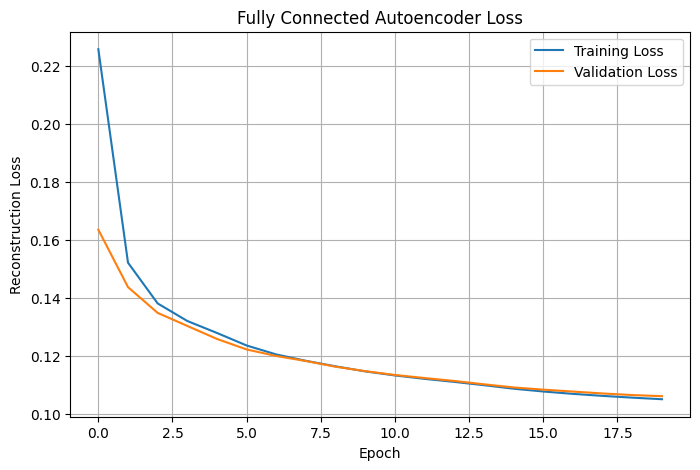

In [6]:
plt.figure(figsize=(8, 5))

plt.plot(history_fc.history["loss"], label="Training Loss")
plt.plot(history_fc.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Reconstruction Loss")
plt.title("Fully Connected Autoencoder Loss")
plt.legend()
plt.grid()
save_fig("02_FC_Training_Validation_Loss")
plt.show()

In [7]:
fc_reconstructed_flat = fc_autoencoder.predict(
    x_test_flat,
    verbose=0
)

fc_reconstructed = fc_reconstructed_flat.reshape(
    -1, 28, 28, 1
)

print("Original shape:", x_test.shape)
print("Reconstructed shape:", fc_reconstructed.shape)

Original shape: (10000, 28, 28, 1)
Reconstructed shape: (10000, 28, 28, 1)


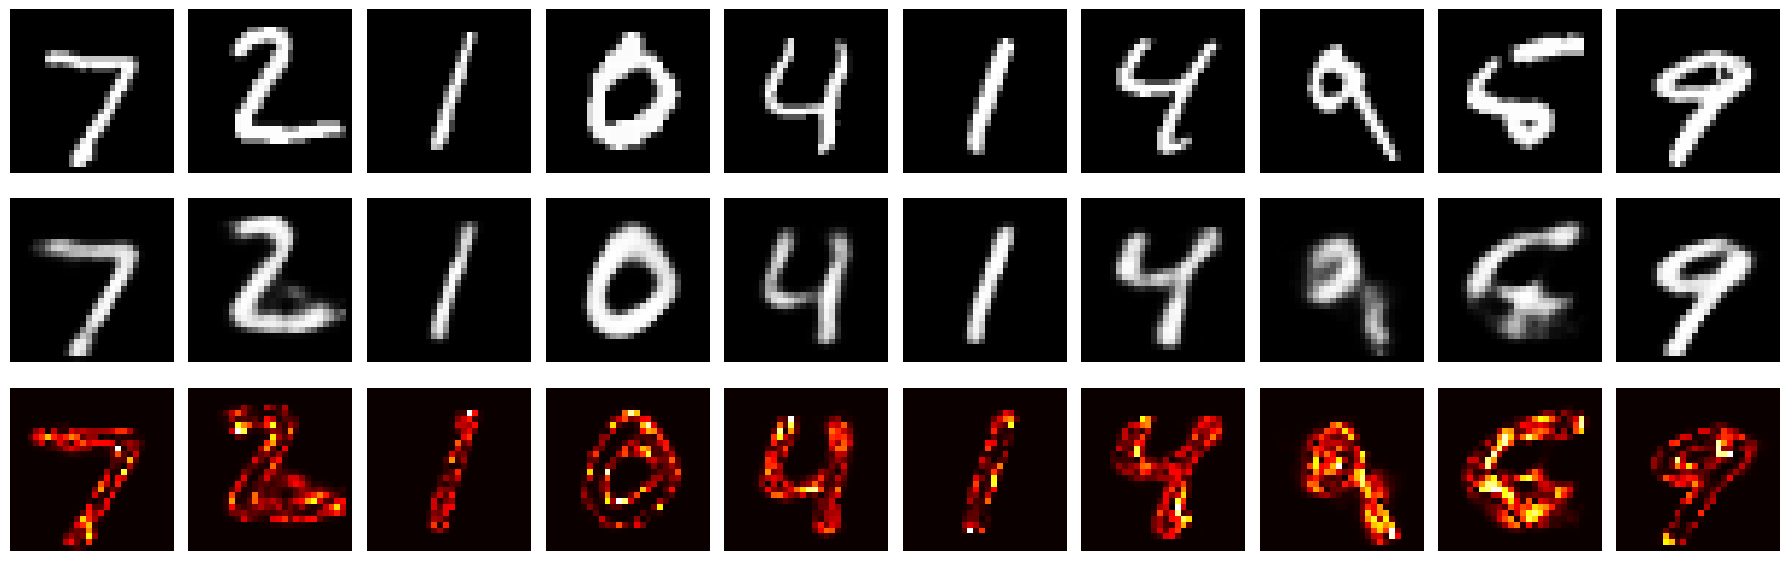

In [8]:
n = 10

fig, axes = plt.subplots(3, n, figsize=(18, 6))

for i in range(n):
    original = x_test[i].squeeze()
    reconstructed = fc_reconstructed[i].squeeze()
    error = np.abs(original - reconstructed)

    axes[0, i].imshow(original, cmap="gray")
    axes[0, i].axis("off")

    axes[1, i].imshow(reconstructed, cmap="gray")
    axes[1, i].axis("off")

    axes[2, i].imshow(error, cmap="hot")
    axes[2, i].axis("off")

axes[0, 0].set_ylabel("Original", fontsize=12)
axes[1, 0].set_ylabel("Reconstructed", fontsize=12)
axes[2, 0].set_ylabel("Error", fontsize=12)

plt.tight_layout()
save_figure(fig, "01_FC_Reconstruction_Error_Images")
plt.show()

In [9]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

fc_mse = mean_squared_error(
    x_test_flat,
    fc_reconstructed_flat
)

fc_mae = mean_absolute_error(
    x_test_flat,
    fc_reconstructed_flat
)

print("FC Autoencoder MSE:", fc_mse)
print("FC Autoencoder MAE:", fc_mae)

FC Autoencoder MSE: 0.014010167680680752
FC Autoencoder MAE: 0.04211743175983429


In [10]:
fc_ssim_scores = []

for i in range(len(x_test)):
    score = ssim(
        x_test[i].squeeze(),
        fc_reconstructed[i].squeeze(),
        data_range=1.0
    )
    fc_ssim_scores.append(score)

fc_ssim = np.mean(fc_ssim_scores)

print("FC Autoencoder Mean SSIM:", fc_ssim)

FC Autoencoder Mean SSIM: 0.8436237640318823


In [11]:
input_layer = layers.Input(shape=(28, 28, 1))

x = layers.Conv2D(
    32, 3, activation="relu", padding="same"
)(input_layer)

x = layers.MaxPooling2D(
    2, padding="same"
)(x)

x = layers.Conv2D(
    64, 3, activation="relu", padding="same"
)(x)

x = layers.MaxPooling2D(
    2, padding="same"
)(x)

x = layers.Conv2D(
    64, 3, activation="relu", padding="same"
)(x)

x = layers.UpSampling2D(2)(x)

x = layers.Conv2D(
    32, 3, activation="relu", padding="same"
)(x)

x = layers.UpSampling2D(2)(x)

output_layer = layers.Conv2D(
    1, 3, activation="sigmoid", padding="same"
)(x)

conv_autoencoder = Model(input_layer, output_layer)

conv_autoencoder.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy"
)

conv_autoencoder.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 28, 28, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 74,497 (291.00 KB)

 Trainable params: 74,497 (291.00 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
history_conv = conv_autoencoder.fit(
    x_train,
    x_train,
    validation_data=(x_val, x_val),
    epochs=20,
    batch_size=128,
    shuffle=True
)

Epoch 1/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - loss: 0.1102 - val_loss: 0.0772
Epoch 2/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0731 - val_loss: 0.0714
Epoch 3/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 0.0704 - val_loss: 0.0697
Epoch 4/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0690 - val_loss: 0.0688
Epoch 5/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0681 - val_loss: 0.0680
Epoch 6/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0674 - val_loss: 0.0673
Epoch 7/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0668 - val_loss: 0.0669
Epoch 8/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0663 - val_loss: 0.0663
Epoch 9/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0658 - val_loss: 0.0660
Epoch 10/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0655 - val_loss: 0.0654
Epoch 11/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0651 - val_loss: 0.0652
Epoch 12/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/st

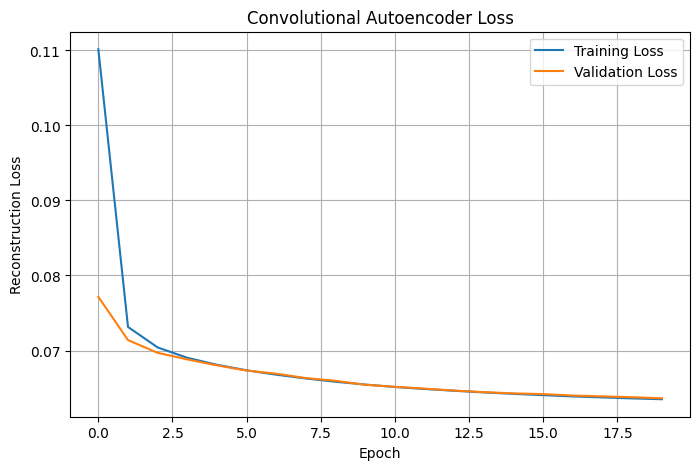

In [13]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_conv.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_conv.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Reconstruction Loss")
plt.title("Convolutional Autoencoder Loss")
plt.legend()
plt.grid()
save_fig("03_Convolutional_AE_Training_Validation_Loss")
plt.show()

In [14]:
conv_reconstructed = conv_autoencoder.predict(
    x_test,
    verbose=0
)

print("Original shape:", x_test.shape)
print("Reconstructed shape:", conv_reconstructed.shape)

Original shape: (10000, 28, 28, 1)
Reconstructed shape: (10000, 28, 28, 1)


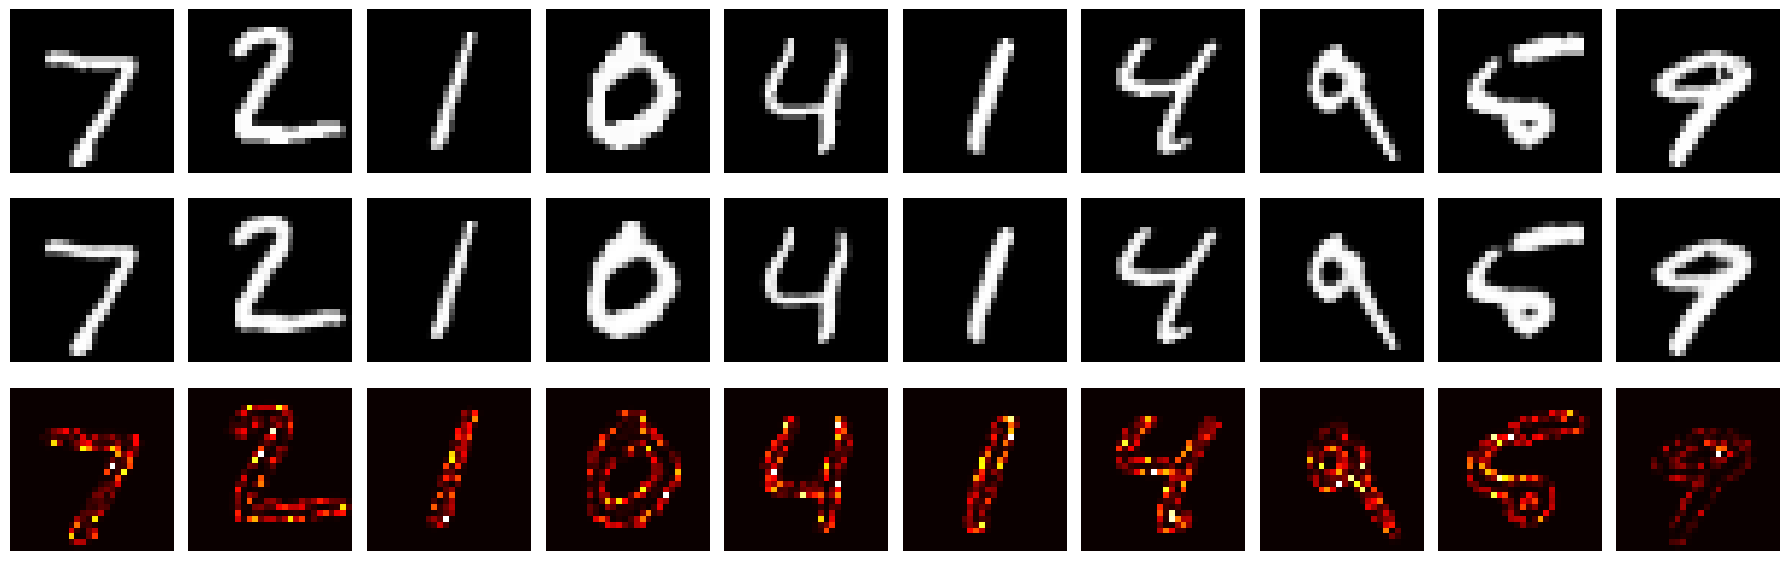

In [15]:
n = 10

fig, axes = plt.subplots(3, n, figsize=(18, 6))

for i in range(n):
    original = x_test[i].squeeze()
    reconstructed = conv_reconstructed[i].squeeze()
    error = np.abs(original - reconstructed)

    axes[0, i].imshow(original, cmap="gray")
    axes[0, i].axis("off")

    axes[1, i].imshow(reconstructed, cmap="gray")
    axes[1, i].axis("off")

    axes[2, i].imshow(error, cmap="hot")
    axes[2, i].axis("off")

axes[0, 0].set_ylabel("Original", fontsize=12)
axes[1, 0].set_ylabel("Reconstructed", fontsize=12)
axes[2, 0].set_ylabel("Error", fontsize=12)

plt.tight_layout()
save_figure(fig, "04_Convolutional_AE_Reconstruction_Error_Images")
plt.show()

In [16]:
conv_mse = mean_squared_error(
    x_test.reshape(len(x_test), -1),
    conv_reconstructed.reshape(len(conv_reconstructed), -1)
)

print("Convolutional Autoencoder MSE:", conv_mse)

Convolutional Autoencoder MSE: 0.001133139245212078


In [17]:
conv_mae = mean_absolute_error(
    x_test.reshape(len(x_test), -1),
    conv_reconstructed.reshape(len(conv_reconstructed), -1)
)

print("Convolutional Autoencoder MAE:", conv_mae)

Convolutional Autoencoder MAE: 0.010078644379973412


In [18]:
conv_ssim_scores = []

for i in range(len(x_test)):
    score = ssim(
        x_test[i].squeeze(),
        conv_reconstructed[i].squeeze(),
        data_range=1.0
    )
    conv_ssim_scores.append(score)

conv_ssim = np.mean(conv_ssim_scores)

print("Convolutional Autoencoder Mean SSIM:", conv_ssim)

Convolutional Autoencoder Mean SSIM: 0.9888069774770478


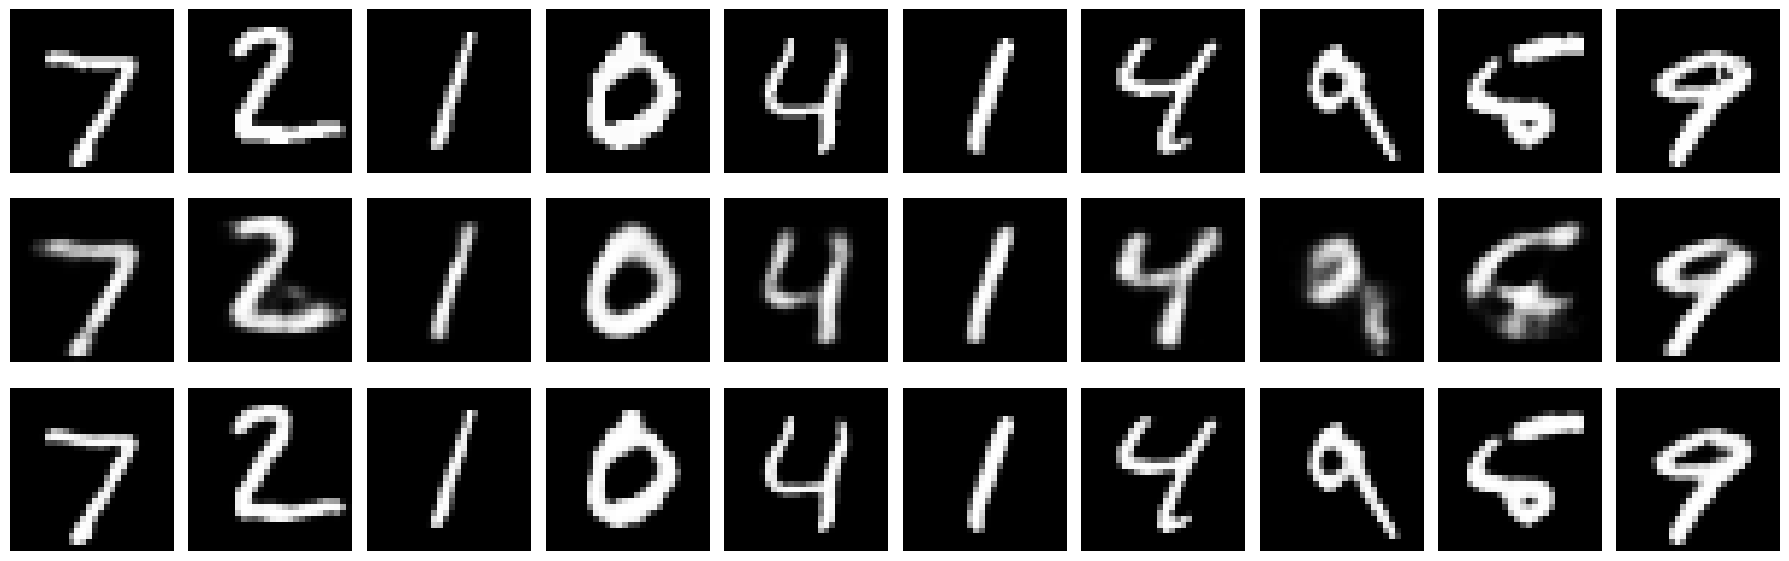

In [19]:
n = 10

fig, axes = plt.subplots(3, n, figsize=(18, 6))

for i in range(n):
    axes[0, i].imshow(
        x_test[i].squeeze(),
        cmap="gray"
    )
    axes[0, i].axis("off")

    axes[1, i].imshow(
        fc_reconstructed[i].squeeze(),
        cmap="gray"
    )
    axes[1, i].axis("off")

    axes[2, i].imshow(
        conv_reconstructed[i].squeeze(),
        cmap="gray"
    )
    axes[2, i].axis("off")

axes[0, 0].set_ylabel("Original", fontsize=12)
axes[1, 0].set_ylabel("FC-AE", fontsize=12)
axes[2, 0].set_ylabel("CAE", fontsize=12)

plt.tight_layout()
save_figure(fig, "05_FC_vs_Convolutional_Reconstruction")
plt.show()

In [20]:
comparison_df = pd.DataFrame({
    "Model": [
        "Fully Connected AE",
        "Convolutional AE"
    ],
    "MSE": [
        fc_mse,
        conv_mse
    ],
    "MAE": [
        fc_mae,
        conv_mae
    ],
    "SSIM": [
        fc_ssim,
        conv_ssim
    ],
    "Parameters": [
        fc_autoencoder.count_params(),
        conv_autoencoder.count_params()
    ]
})

comparison_df

,Model,MSE,MAE,SSIM,Parameters
0,Fully Connected AE,0.014010,0.042117,0.843624,211040
1,Convolutional AE,0.001133,0.010079,0.988807,74497


In [21]:
def add_gaussian_noise(images, sigma):
    noise = np.random.normal(0, sigma, images.shape)
    noisy_images = images + noise
    return np.clip(noisy_images, 0, 1)

def add_salt_pepper_noise(images, probability):
    noisy_images = images.copy()

    random_values = np.random.rand(*images.shape)

    noisy_images[random_values < probability / 2] = 0
    noisy_images[
        (random_values >= probability / 2) &
        (random_values < probability)
    ] = 1

    return noisy_images

In [22]:
gaussian_sigma = 0.2

x_train_noisy = add_gaussian_noise(
    x_train,
    gaussian_sigma
)

x_val_noisy = add_gaussian_noise(
    x_val,
    gaussian_sigma
)

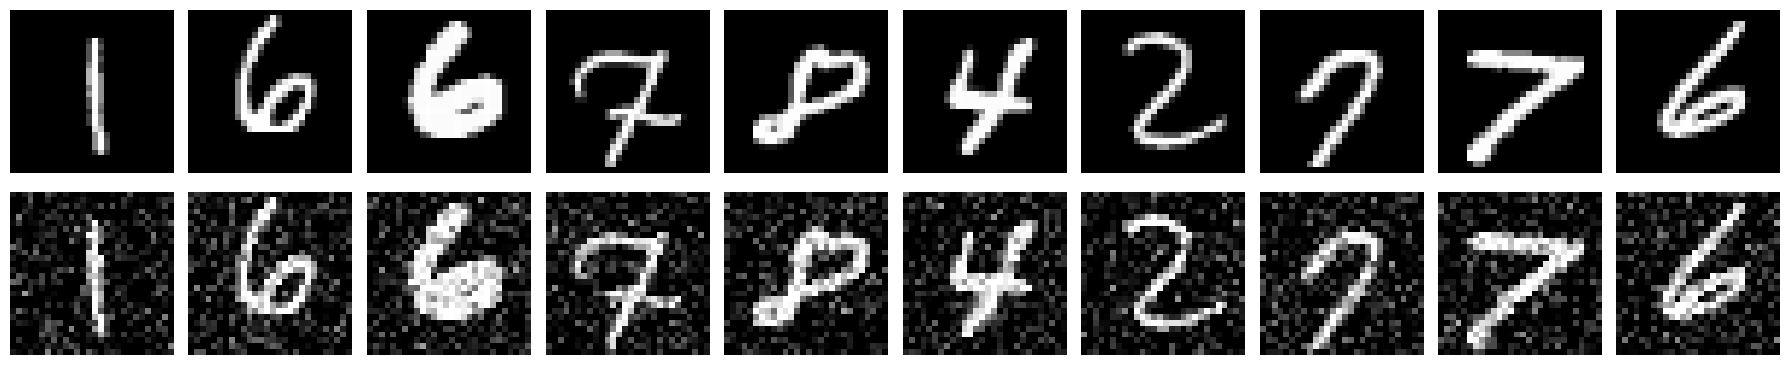

In [23]:
n = 10

fig, axes = plt.subplots(2, n, figsize=(18, 4))

for i in range(n):
    axes[0, i].imshow(x_train[i].squeeze(), cmap="gray")
    axes[0, i].axis("off")

    axes[1, i].imshow(x_train_noisy[i].squeeze(), cmap="gray")
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Clean", fontsize=12)
axes[1, 0].set_ylabel("Noisy", fontsize=12)

plt.tight_layout()
save_figure(fig, "06_Clean_vs_Noisy_Training_Images")
plt.show()

In [24]:
input_layer = layers.Input(shape=(28, 28, 1))

x = layers.Conv2D(
    32, 3, activation="relu", padding="same"
)(input_layer)

x = layers.MaxPooling2D(
    2, padding="same"
)(x)

x = layers.Conv2D(
    64, 3, activation="relu", padding="same"
)(x)

x = layers.MaxPooling2D(
    2, padding="same"
)(x)

x = layers.Conv2D(
    64, 3, activation="relu", padding="same"
)(x)

x = layers.UpSampling2D(2)(x)

x = layers.Conv2D(
    32, 3, activation="relu", padding="same"
)(x)

x = layers.UpSampling2D(2)(x)

output_layer = layers.Conv2D(
    1, 3, activation="sigmoid", padding="same"
)(x)

denoising_autoencoder = Model(
    input_layer,
    output_layer
)

denoising_autoencoder.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy"
)

denoising_autoencoder.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 7, 7, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_2 (UpSampling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 14, 14, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_3 (UpSampling2D)  │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 28, 28, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 74,497 (291.00 KB)

 Trainable params: 74,497 (291.00 KB)

 Non-trainable params: 0 (0.00 B)

In [25]:
history_denoising = denoising_autoencoder.fit(
    x_train_noisy,
    x_train,
    validation_data=(x_val_noisy, x_val),
    epochs=20,
    batch_size=128,
    shuffle=True
)

Epoch 1/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - loss: 0.1252 - val_loss: 0.0838
Epoch 2/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0803 - val_loss: 0.0787
Epoch 3/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0771 - val_loss: 0.0764
Epoch 4/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0755 - val_loss: 0.0752
Epoch 5/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 0.0745 - val_loss: 0.0743
Epoch 6/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0737 - val_loss: 0.0736
Epoch 7/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0731 - val_loss: 0.0731
Epoch 8/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - loss: 0.0726 - val_loss: 0.0727
Epoch 9/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 0.0722 - val_loss: 0.0724
Epoch 10/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0719 - val_loss: 0.0721
Epoch 11/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0716 - val_loss: 0.0718
Epoch 12/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/ste

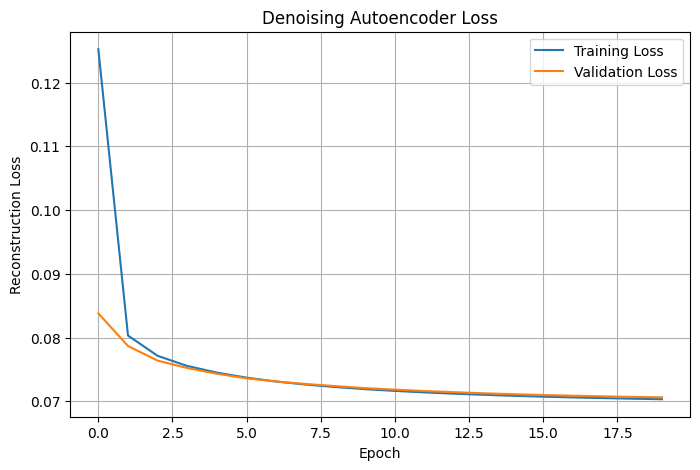

In [26]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_denoising.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_denoising.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Reconstruction Loss")
plt.title("Denoising Autoencoder Loss")
plt.legend()
plt.grid()
save_fig("07_Denoising_AE_Training_Validation_Loss")
plt.show()

In [27]:
x_test_noisy = add_gaussian_noise(
    x_test,
    gaussian_sigma
)

x_test_denoised = denoising_autoencoder.predict(
    x_test_noisy,
    verbose=0
)

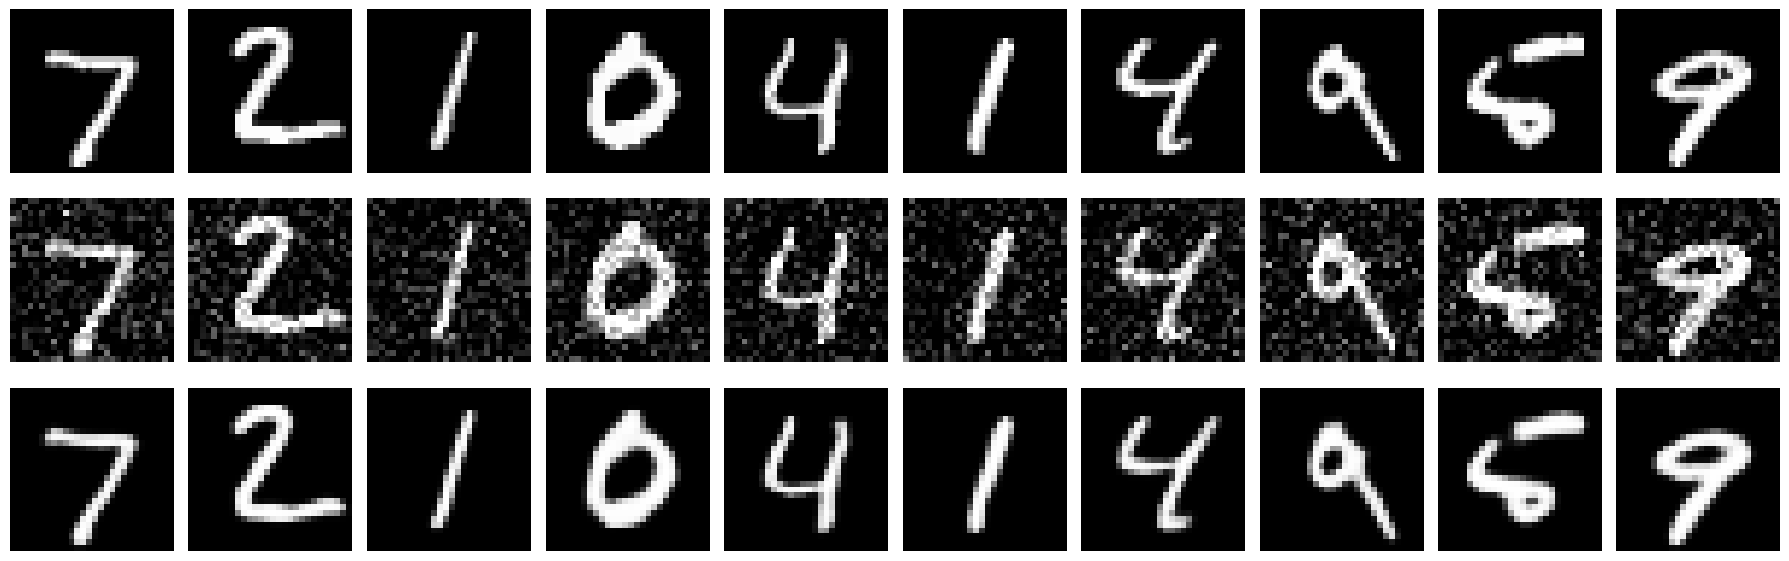

In [28]:
n = 10

fig, axes = plt.subplots(3, n, figsize=(18, 6))

for i in range(n):
    axes[0, i].imshow(
        x_test[i].squeeze(),
        cmap="gray"
    )
    axes[0, i].axis("off")

    axes[1, i].imshow(
        x_test_noisy[i].squeeze(),
        cmap="gray"
    )
    axes[1, i].axis("off")

    axes[2, i].imshow(
        x_test_denoised[i].squeeze(),
        cmap="gray"
    )
    axes[2, i].axis("off")

axes[0, 0].set_ylabel("Clean", fontsize=12)
axes[1, 0].set_ylabel("Noisy", fontsize=12)
axes[2, 0].set_ylabel("Denoised", fontsize=12)

plt.tight_layout()
save_figure(fig, "08_Clean_Noisy_Denoised")
plt.show()

In [29]:
def calculate_metrics(original, reconstructed):
    original_flat = original.reshape(len(original), -1)
    reconstructed_flat = reconstructed.reshape(len(reconstructed), -1)

    mse = mean_squared_error(
        original_flat,
        reconstructed_flat
    )

    mae = mean_absolute_error(
        original_flat,
        reconstructed_flat
    )

    ssim_scores = []

    for i in range(len(original)):
        score = ssim(
            original[i].squeeze(),
            reconstructed[i].squeeze(),
            data_range=1.0
        )
        ssim_scores.append(score)

    return mse, mae, np.mean(ssim_scores)

In [30]:
denoise_mse, denoise_mae, denoise_ssim = calculate_metrics(
    x_test,
    x_test_denoised
)

print("MSE:", denoise_mse)
print("MAE:", denoise_mae)
print("SSIM:", denoise_ssim)

MSE: 0.0030117996502667665
MAE: 0.016943326219916344
SSIM: 0.9624978536061157


In [31]:
gaussian_results = []
gaussian_levels = [0.1,0.2,0.3]
for sigma in gaussian_levels:
    noisy_test = add_gaussian_noise(
        x_test,
        sigma
    )

    denoised_test = denoising_autoencoder.predict(
        noisy_test,
        verbose=0
    )

    mse, mae, ssim_value = calculate_metrics(
        x_test,
        denoised_test
    )

    gaussian_results.append([
        sigma,
        mse,
        mae,
        ssim_value
    ])

gaussian_results_df = pd.DataFrame(
    gaussian_results,
    columns=["Noise Level", "MSE", "MAE", "SSIM"]
)

gaussian_results_df

,Noise Level,MSE,MAE,SSIM
0,0.1,0.002061,0.013650,0.975110
1,0.2,0.003017,0.016957,0.962421
2,0.3,0.005750,0.026295,0.878240


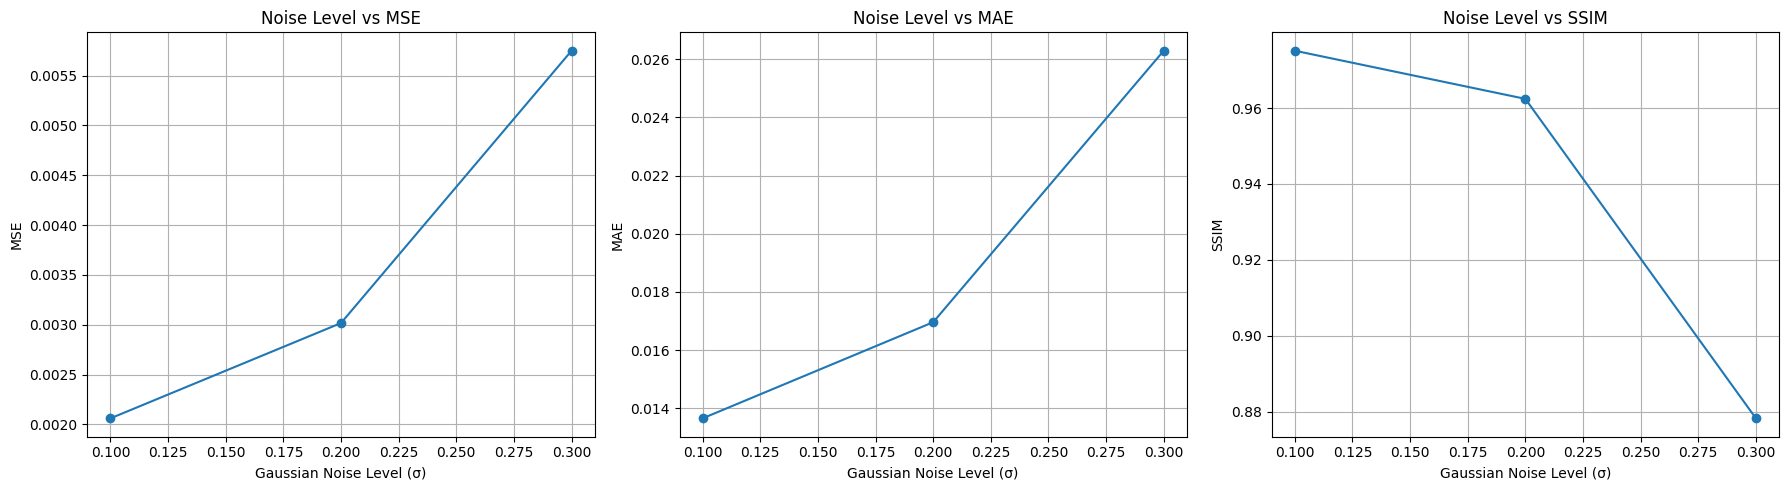

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(
    gaussian_results_df["Noise Level"],
    gaussian_results_df["MSE"],
    marker="o"
)
axes[0].set_xlabel("Gaussian Noise Level (σ)")
axes[0].set_ylabel("MSE")
axes[0].set_title("Noise Level vs MSE")
axes[0].grid()

axes[1].plot(
    gaussian_results_df["Noise Level"],
    gaussian_results_df["MAE"],
    marker="o"
)
axes[1].set_xlabel("Gaussian Noise Level (σ)")
axes[1].set_ylabel("MAE")
axes[1].set_title("Noise Level vs MAE")
axes[1].grid()

axes[2].plot(
    gaussian_results_df["Noise Level"],
    gaussian_results_df["SSIM"],
    marker="o"
)
axes[2].set_xlabel("Gaussian Noise Level (σ)")
axes[2].set_ylabel("SSIM")
axes[2].set_title("Noise Level vs SSIM")
axes[2].grid()

plt.tight_layout()
save_figure(fig, "09_Gaussian_Noise_MSE_MAE_SSIM")
plt.show()

In [33]:
salt_pepper_results = []
salt_pepper_levels = [0.05,0.10,0.20]
for probability in salt_pepper_levels:
    noisy_test = add_salt_pepper_noise(
        x_test,
        probability
    )

    denoised_test = denoising_autoencoder.predict(
        noisy_test,
        verbose=0
    )

    mse, mae, ssim_value = calculate_metrics(
        x_test,
        denoised_test
    )

    salt_pepper_results.append([
        probability,
        mse,
        mae,
        ssim_value
    ])

salt_pepper_results_df = pd.DataFrame(
    salt_pepper_results,
    columns=["Noise Level", "MSE", "MAE", "SSIM"]
)

salt_pepper_results_df

,Noise Level,MSE,MAE,SSIM
0,0.05,0.004193,0.019843,0.912766
1,0.10,0.008260,0.031467,0.810776
2,0.20,0.020739,0.063739,0.644821


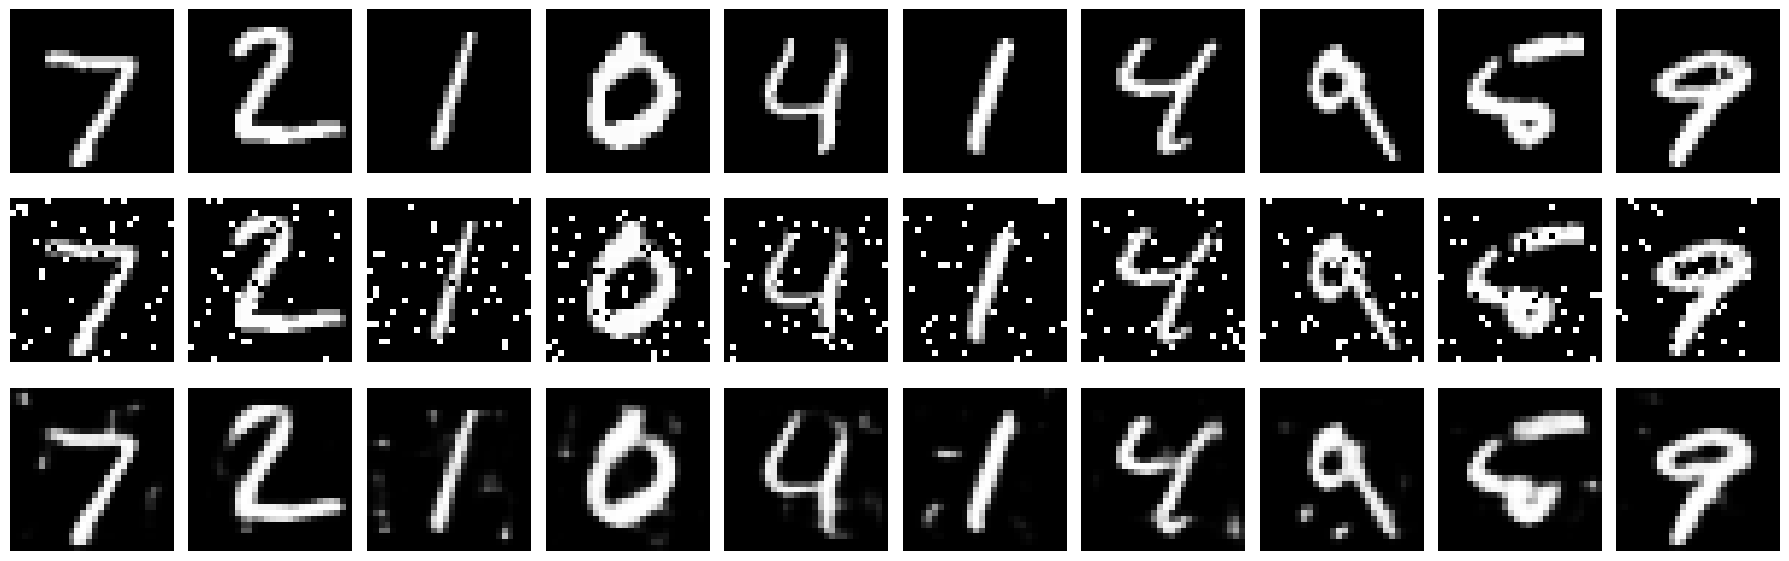

In [34]:
sp_test_noisy = add_salt_pepper_noise(
    x_test,
    0.10
)

sp_test_denoised = denoising_autoencoder.predict(
    sp_test_noisy,
    verbose=0
)

n = 10

fig, axes = plt.subplots(3, n, figsize=(18, 6))

for i in range(n):
    axes[0, i].imshow(
        x_test[i].squeeze(),
        cmap="gray"
    )
    axes[0, i].axis("off")

    axes[1, i].imshow(
        sp_test_noisy[i].squeeze(),
        cmap="gray"
    )
    axes[1, i].axis("off")

    axes[2, i].imshow(
        sp_test_denoised[i].squeeze(),
        cmap="gray"
    )
    axes[2, i].axis("off")

axes[0, 0].set_ylabel("Clean", fontsize=12)
axes[1, 0].set_ylabel("Noisy", fontsize=12)
axes[2, 0].set_ylabel("Denoised", fontsize=12)

plt.tight_layout()
save_figure(fig, "10_Salt_Pepper_Clean_Noisy_Denoised")
plt.show()

In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, Model
from sklearn.metrics import mean_squared_error, mean_absolute_error
from skimage.metrics import structural_similarity as ssim


latent_dim = 2


class Sampling(layers.Layer):
    def call(self, inputs):
        mu, log_var = inputs
        epsilon = tf.random.normal(
            shape=tf.shape(mu)
        )
        return mu + tf.exp(0.5 * log_var) * epsilon


encoder_inputs = layers.Input(
    shape=(28, 28, 1),
    name="encoder_input"
)

x = layers.Conv2D(
    32,
    3,
    activation="relu",
    padding="same"
)(encoder_inputs)

x = layers.MaxPooling2D(
    2,
    padding="same"
)(x)

x = layers.Conv2D(
    64,
    3,
    activation="relu",
    padding="same"
)(x)

x = layers.MaxPooling2D(
    2,
    padding="same"
)(x)

x = layers.Conv2D(
    64,
    3,
    activation="relu",
    padding="same"
)(x)

x = layers.Flatten()(x)

mu = layers.Dense(
    latent_dim,
    name="mu"
)(x)

log_var = layers.Dense(
    latent_dim,
    name="log_var"
)(x)

z = Sampling()([mu, log_var])

encoder = Model(
    encoder_inputs,
    [mu, log_var, z],
    name="encoder"
)

encoder.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 28, 28, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_10 (Conv2D)  │ (None, 28, 28,    │        320 │ encoder_input[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_4     │ (None, 14, 14,    │          0 │ conv2d_10[0][0]   │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_11 (Conv2D)  │ (None, 14, 14,    │     18,496 │ max_pooling2d_4[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_5     │ (None, 7, 7, 64)  │          0 │ conv2d_11[0][0]   │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_12 (Conv2D)  │ (None, 7, 7, 64)  │     36,928 │ max_pooling2d_5[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 3136)      │          0 │ conv2d_12[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mu (Dense)          │ (None, 2)         │      6,274 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ log_var (Dense)     │ (None, 2)         │      6,274 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sampling (Sampling) │ (None, 2)         │          0 │ mu[0][0],         │
│                     │                   │            │ log_var[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 68,292 (266.77 KB)

 Trainable params: 68,292 (266.77 KB)

 Non-trainable params: 0 (0.00 B)

In [36]:
latent_inputs = layers.Input(
    shape=(latent_dim,),
    name="decoder_input"
)

x = layers.Dense(
    7 * 7 * 64,
    activation="relu"
)(latent_inputs)

x = layers.Reshape(
    (7, 7, 64)
)(x)

x = layers.Conv2DTranspose(
    64,
    3,
    strides=2,
    activation="relu",
    padding="same"
)(x)

x = layers.Conv2DTranspose(
    32,
    3,
    strides=2,
    activation="relu",
    padding="same"
)(x)

decoder_outputs = layers.Conv2D(
    1,
    3,
    activation="sigmoid",
    padding="same"
)(x)

decoder = Model(
    latent_inputs,
    decoder_outputs,
    name="decoder"
)

decoder.summary()

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ decoder_input (InputLayer)      │ (None, 2)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3136)           │         9,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 64)     │        36,928 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 32)     │        18,464 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 28, 28, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 65,089 (254.25 KB)

 Trainable params: 65,089 (254.25 KB)

 Non-trainable params: 0 (0.00 B)

In [37]:
vae_inputs = layers.Input(
    shape=(28, 28, 1),
    name="vae_input"
)

mu, log_var, z = encoder(vae_inputs)

vae_outputs = decoder(z)

vae = Model(
    vae_inputs,
    vae_outputs,
    name="vae"
)

vae.summary()

Model: "vae"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vae_input (InputLayer)          │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder (Functional)            │ [(None, 2), (None, 2), │        68,292 │
│                                 │ (None, 2)]             │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Functional)            │ (None, 28, 28, 1)      │        65,089 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 133,381 (521.02 KB)

 Trainable params: 133,381 (521.02 KB)

 Non-trainable params: 0 (0.00 B)

In [38]:
def reconstruction_loss(y_true, y_pred):
    bce = tf.keras.backend.binary_crossentropy(
        y_true,
        y_pred
    )

    return tf.reduce_sum(
        bce,
        axis=[1, 2]
    )


def kl_loss(mu, log_var):
    return -0.5 * tf.reduce_sum(
        1 + log_var - tf.square(mu) - tf.exp(log_var),
        axis=1
    )

In [39]:
optimizer = tf.keras.optimizers.Adam(
    learning_rate=1e-3
)

train_loss_history = []
val_loss_history = []

train_reconstruction_history = []
val_reconstruction_history = []

train_kl_history = []
val_kl_history = []



@tf.function
def train_step(images):
    with tf.GradientTape() as tape:
        mu, log_var, z = encoder(images, training=True)

        reconstructed = decoder(
            z,
            training=True
        )

        rec_loss = reconstruction_loss(
            images,
            reconstructed
        )

        kl = kl_loss(
            mu,
            log_var
        )

        total = rec_loss + kl

        total_loss = tf.reduce_mean(total)
        reconstruction_mean = tf.reduce_mean(rec_loss)
        kl_mean = tf.reduce_mean(kl)

    gradients = tape.gradient(
        total_loss,
        vae.trainable_variables
    )

    optimizer.apply_gradients(
        zip(
            gradients,
            vae.trainable_variables
        )
    )

    return (
        total_loss,
        reconstruction_mean,
        kl_mean
    )


@tf.function
def validation_step(images):
    mu, log_var, z = encoder(
        images,
        training=False
    )

    reconstructed = decoder(
        z,
        training=False
    )

    rec_loss = reconstruction_loss(
        images,
        reconstructed
    )

    kl = kl_loss(
        mu,
        log_var
    )

    total = rec_loss + kl

    return (
        tf.reduce_mean(total),
        tf.reduce_mean(rec_loss),
        tf.reduce_mean(kl)
    )

In [40]:
batch_size = 128
epochs = 20

train_dataset = tf.data.Dataset.from_tensor_slices(
    x_train
).shuffle(
    len(x_train)
).batch(
    batch_size
)

val_dataset = tf.data.Dataset.from_tensor_slices(
    x_val
).batch(
    batch_size
)


for epoch in range(epochs):

    train_total = []
    train_rec = []
    train_kl = []

    for batch in train_dataset:
        total, rec, kl = train_step(batch)

        train_total.append(total.numpy())
        train_rec.append(rec.numpy())
        train_kl.append(kl.numpy())

    val_total = []
    val_rec = []
    val_kl = []

    for batch in val_dataset:
        total, rec, kl = validation_step(batch)

        val_total.append(total.numpy())
        val_rec.append(rec.numpy())
        val_kl.append(kl.numpy())

    train_loss_history.append(np.mean(train_total))
    train_reconstruction_history.append(np.mean(train_rec))
    train_kl_history.append(np.mean(train_kl))

    val_loss_history.append(np.mean(val_total))
    val_reconstruction_history.append(np.mean(val_rec))
    val_kl_history.append(np.mean(val_kl))

    print(
        f"Epoch {epoch + 1}/{epochs} "
        f"- loss: {train_loss_history[-1]:.4f} "
        f"- rec: {train_reconstruction_history[-1]:.4f} "
        f"- kl: {train_kl_history[-1]:.4f} "
        f"- val_loss: {val_loss_history[-1]:.4f}"
    )

Epoch 1/20 - loss: 202.3776 - rec: 198.1750 - kl: 4.2026 - val_loss: 171.5762
Epoch 2/20 - loss: 165.0701 - rec: 160.0559 - kl: 5.0142 - val_loss: 160.1113
Epoch 3/20 - loss: 158.0785 - rec: 152.5896 - kl: 5.4889 - val_loss: 156.7027
Epoch 4/20 - loss: 154.8958 - rec: 149.1807 - kl: 5.7152 - val_loss: 153.5804
Epoch 5/20 - loss: 152.7464 - rec: 146.8763 - kl: 5.8701 - val_loss: 151.8399
Epoch 6/20 - loss: 151.3645 - rec: 145.4073 - kl: 5.9573 - val_loss: 151.0364
Epoch 7/20 - loss: 150.2769 - rec: 144.2323 - kl: 6.0446 - val_loss: 149.8824
Epoch 8/20 - loss: 149.4226 - rec: 143.3145 - kl: 6.1081 - val_loss: 149.6989
Epoch 9/20 - loss: 148.7198 - rec: 142.5822 - kl: 6.1376 - val_loss: 148.7322
Epoch 10/20 - loss: 148.0159 - rec: 141.8239 - kl: 6.1920 - val_loss: 148.4910
Epoch 11/20 - loss: 147.5930 - rec: 141.3512 - kl: 6.2418 - val_loss: 148.4718
Epoch 12/20 - loss: 147.0957 - rec: 140.8376 - kl: 6.2581 - val_loss: 147.8306
Epoch 13/20 - loss: 146.6649 - rec: 140.3700 - kl: 6.2948 - v

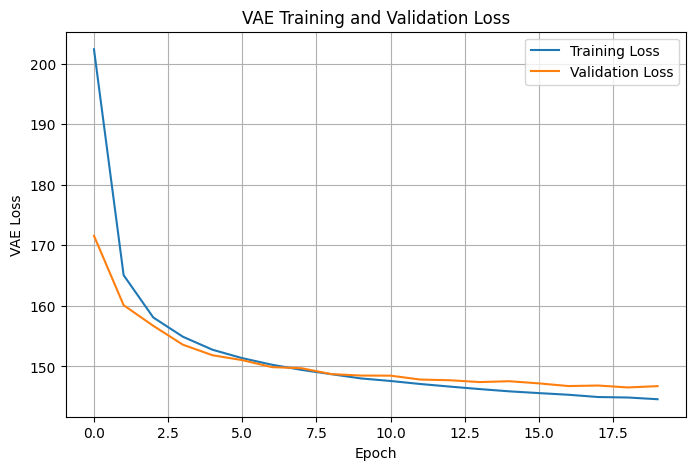

In [41]:
plt.figure(figsize=(8, 5))

plt.plot(
    train_loss_history,
    label="Training Loss"
)

plt.plot(
    val_loss_history,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("VAE Loss")
plt.title("VAE Training and Validation Loss")
plt.legend()
plt.grid()
save_fig("11_VAE_Training_Validation_Loss")
plt.show()

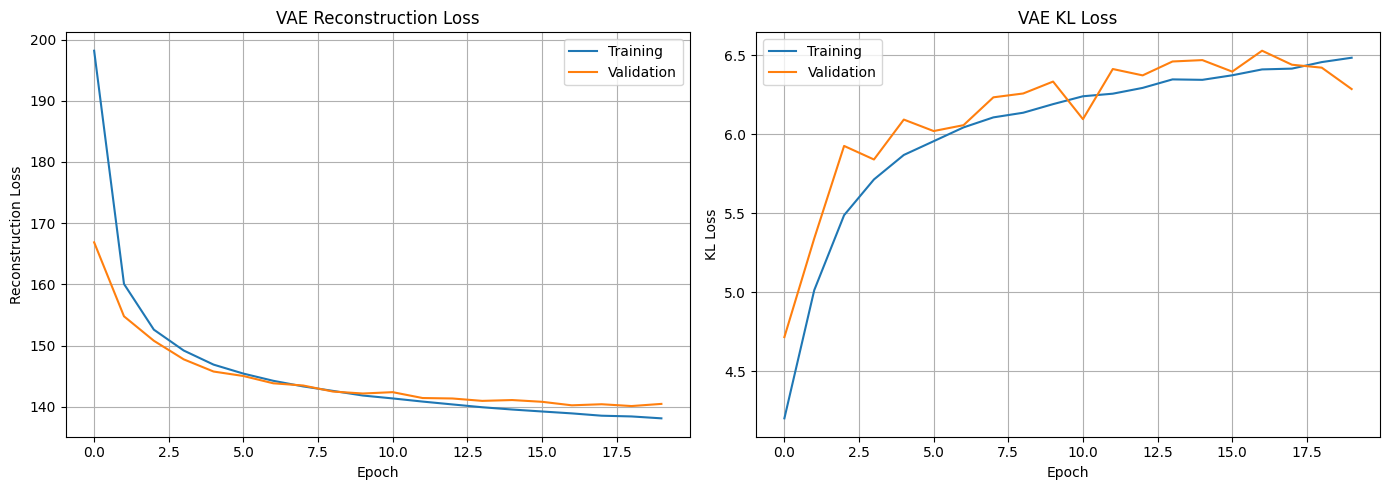

In [42]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

axes[0].plot(
    train_reconstruction_history,
    label="Training"
)

axes[0].plot(
    val_reconstruction_history,
    label="Validation"
)

axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Reconstruction Loss")
axes[0].set_title("VAE Reconstruction Loss")
axes[0].legend()
axes[0].grid()


axes[1].plot(
    train_kl_history,
    label="Training"
)

axes[1].plot(
    val_kl_history,
    label="Validation"
)

axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("KL Loss")
axes[1].set_title("VAE KL Loss")
axes[1].legend()
axes[1].grid()

plt.tight_layout()
save_figure(fig, "12_VAE_Reconstruction_and_KL_Loss")
plt.show()

In [43]:
test_mu, test_log_var, test_z = encoder(
    x_test,
    training=False
)

vae_reconstructed = decoder(
    test_z,
    training=False
).numpy()

print("Original:", x_test.shape)
print("VAE reconstruction:", vae_reconstructed.shape)

Original: (10000, 28, 28, 1)
VAE reconstruction: (10000, 28, 28, 1)


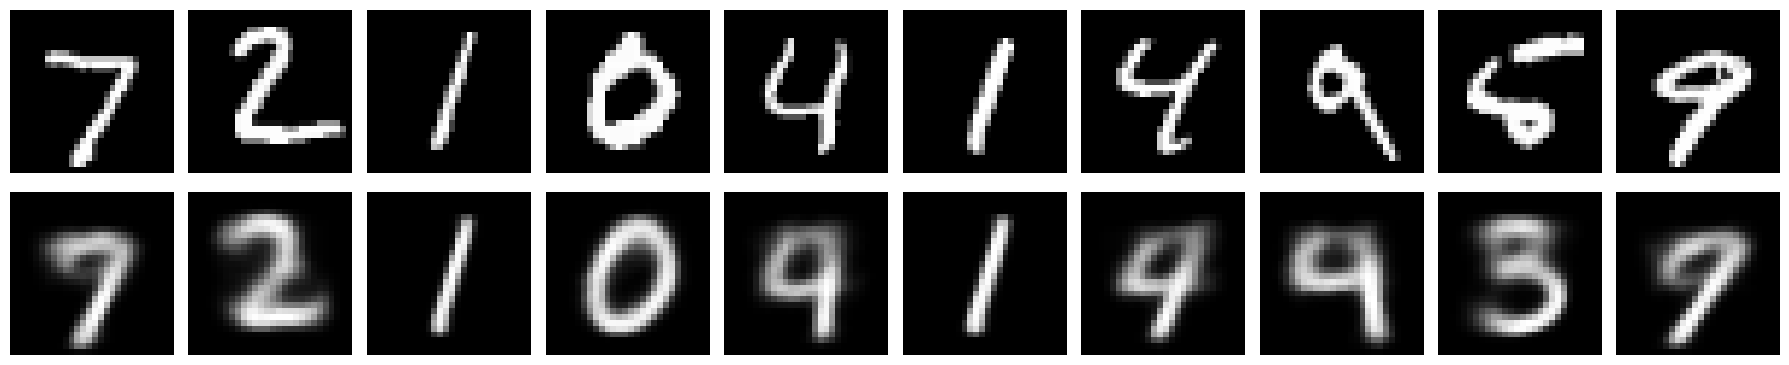

In [44]:
n = 10

fig, axes = plt.subplots(
    2,
    n,
    figsize=(18, 4)
)

for i in range(n):

    axes[0, i].imshow(
        x_test[i].squeeze(),
        cmap="gray"
    )
    axes[0, i].axis("off")

    axes[1, i].imshow(
        vae_reconstructed[i].squeeze(),
        cmap="gray"
    )
    axes[1, i].axis("off")

axes[0, 0].set_ylabel(
    "Original",
    fontsize=12
)

axes[1, 0].set_ylabel(
    "VAE",
    fontsize=12
)

plt.tight_layout()
save_figure(fig, "13_VAE_Reconstruction")
plt.show()

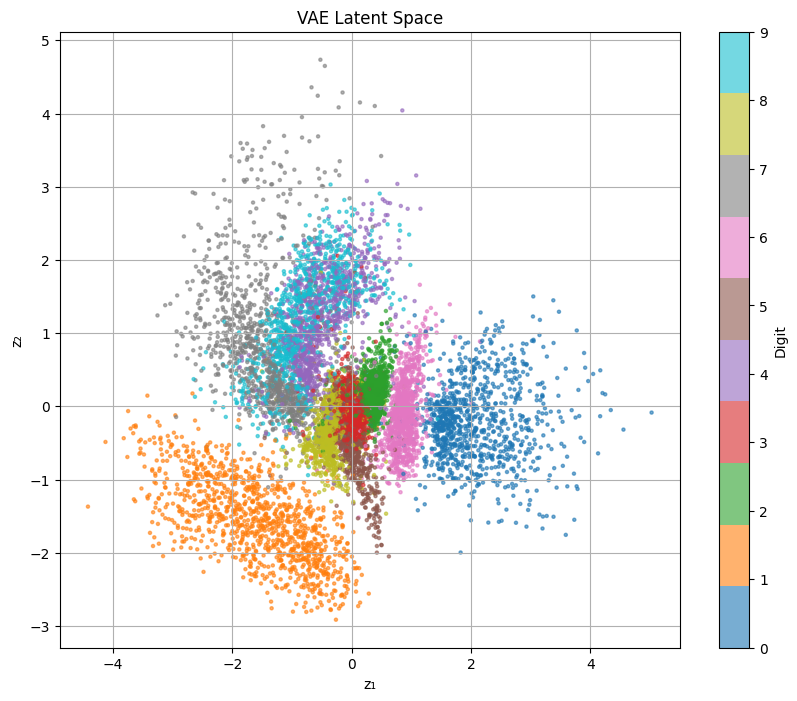

In [45]:
(_, y_train), (x_test_original, y_test) = tf.keras.datasets.mnist.load_data()

latent_mu, _, _ = encoder(
    x_test,
    training=False
)

latent_mu = latent_mu.numpy()

plt.figure(figsize=(10, 8))

scatter = plt.scatter(
    latent_mu[:, 0],
    latent_mu[:, 1],
    c=y_test,
    cmap="tab10",
    s=5,
    alpha=0.6
)

plt.xlabel("z₁")
plt.ylabel("z₂")
plt.title("VAE Latent Space")
plt.colorbar(
    scatter,
    ticks=range(10),
    label="Digit"
)

plt.grid()
save_fig("14_VAE_Latent_Space")
plt.show()

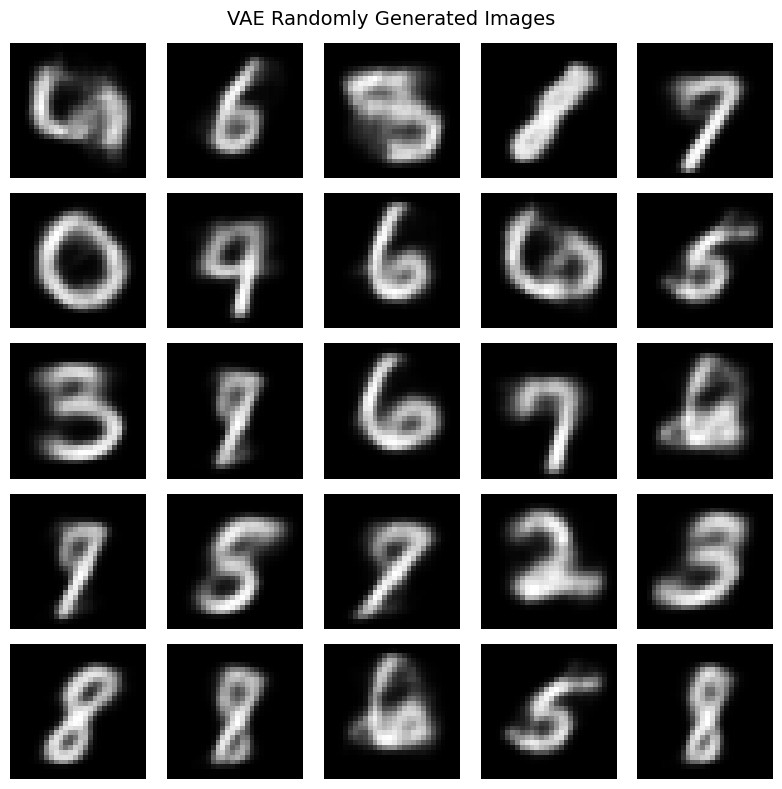

In [46]:
num_samples = 25

random_latent_vectors = np.random.normal(
    size=(num_samples, latent_dim)
).astype("float32")

generated_images = decoder.predict(
    random_latent_vectors,
    verbose=0
)

fig, axes = plt.subplots(
    5,
    5,
    figsize=(8, 8)
)

for i, ax in enumerate(axes.ravel()):
    ax.imshow(
        generated_images[i].squeeze(),
        cmap="gray"
    )
    ax.axis("off")

plt.suptitle(
    "VAE Randomly Generated Images",
    fontsize=14
)

plt.tight_layout()
save_figure(fig, "15_VAE_25_Random_Generated_Images")
plt.show()

z_A: [-1.6493437   0.89573306]
z_B: [0.23634359 0.3507254 ]


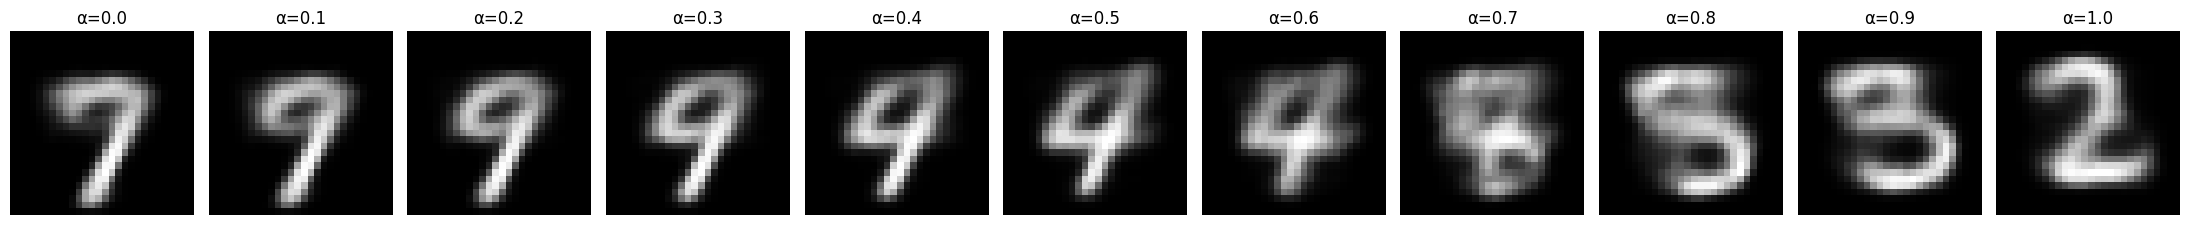

In [47]:
index_a = 0
index_b = 1

z_a = latent_mu[index_a]
z_b = latent_mu[index_b]

print("z_A:", z_a)
print("z_B:", z_b)

alphas = np.linspace(
    0,
    1,
    11
)

interpolated_latents = np.array([
    (1 - alpha) * z_a + alpha * z_b
    for alpha in alphas
]).astype("float32")

interpolated_images = decoder.predict(
    interpolated_latents,
    verbose=0
)

fig, axes = plt.subplots(
    1,
    11,
    figsize=(22, 3)
)

for i, ax in enumerate(axes):

    ax.imshow(
        interpolated_images[i].squeeze(),
        cmap="gray"
    )

    ax.set_title(
        f"α={alphas[i]:.1f}"
    )

    ax.axis("off")

plt.tight_layout()
save_figure(fig, "16_VAE_Latent_Interpolation")
plt.show()

In [48]:
vae_test_mse = mean_squared_error(
    x_test.reshape(len(x_test), -1),
    vae_reconstructed.reshape(len(vae_reconstructed), -1)
)

print("VAE Test MSE:", vae_test_mse)

vae_test_mae = mean_absolute_error(
    x_test.reshape(len(x_test), -1),
    vae_reconstructed.reshape(len(vae_reconstructed), -1)
)

print("VAE Test MAE:", vae_test_mae)

vae_ssim_scores = []

for i in range(len(x_test)):

    score = ssim(
        x_test[i].squeeze(),
        vae_reconstructed[i].squeeze(),
        data_range=1.0
    )

    vae_ssim_scores.append(score)

vae_mean_ssim = np.mean(
    vae_ssim_scores
)

print("VAE Mean SSIM:", vae_mean_ssim)

VAE Test MSE: 0.03933136165142059
VAE Test MAE: 0.09396269172430038
VAE Mean SSIM: 0.5598544363085431


In [49]:
test_mu, test_log_var, test_z = encoder(
    x_test,
    training=False
)

test_reconstructed = decoder(
    test_z,
    training=False
)

test_rec_loss = reconstruction_loss(
    x_test,
    test_reconstructed
)

test_kl_loss = kl_loss(
    test_mu,
    test_log_var
)

vae_reconstruction_loss = tf.reduce_mean(
    test_rec_loss
).numpy()

vae_kl_loss = tf.reduce_mean(
    test_kl_loss
).numpy()

vae_total_loss = (
    vae_reconstruction_loss +
    vae_kl_loss
)

print("Reconstruction Loss:", vae_reconstruction_loss)
print("KL Loss:", vae_kl_loss)
print("Total Loss:", vae_total_loss)
print("Test MSE:", vae_test_mse)
print("Test MAE:", vae_test_mae)
print("Mean SSIM:", vae_mean_ssim)

Reconstruction Loss: 140.21153
KL Loss: 6.2864714
Total Loss: 146.498
Test MSE: 0.03933136165142059
Test MAE: 0.09396269172430038
Mean SSIM: 0.5598544363085431


In [50]:
vae_metrics_df = pd.DataFrame({
    "VAE Metric": [
        "Reconstruction Loss",
        "KL Loss",
        "Total Loss",
        "Test MSE",
        "Test MAE",
        "Mean SSIM"
    ],
    "Value": [
        vae_reconstruction_loss,
        vae_kl_loss,
        vae_total_loss,
        vae_test_mse,
        vae_test_mae,
        vae_mean_ssim
    ]
})

vae_metrics_df

,VAE Metric,Value
0,Reconstruction Loss,140.211533
1,KL Loss,6.286471
2,Total Loss,146.498001
3,Test MSE,0.039331
4,Test MAE,0.093963
5,Mean SSIM,0.559854


In [51]:
final_comparison_df = pd.DataFrame({
    "Model": [
        "Fully Connected AE",
        "Convolutional AE",
        "Denoising CAE"
    ],
    "MSE": [
        fc_mse,
        conv_mse,
        denoise_mse
    ],
    "MAE": [
        fc_mae,
        conv_mae,
        denoise_mae
    ],
    "SSIM": [
        fc_ssim,
        conv_ssim,
        denoise_ssim
    ],
    "Parameters": [
        fc_autoencoder.count_params(),
        conv_autoencoder.count_params(),
        denoising_autoencoder.count_params()
    ]
})

final_comparison_df

,Model,MSE,MAE,SSIM,Parameters
0,Fully Connected AE,0.014010,0.042117,0.843624,211040
1,Convolutional AE,0.001133,0.010079,0.988807,74497
2,Denoising CAE,0.003012,0.016943,0.962498,74497


In [52]:
print("=" * 60)
print("RECONSTRUCTION MODEL COMPARISON")
print("=" * 60)

print(final_comparison_df.to_string(index=False))

print("\n" + "=" * 60)
print("VAE METRICS")
print("=" * 60)

print(vae_metrics_df.to_string(index=False))

print("\n" + "=" * 60)
print("GAUSSIAN DENOISING RESULTS")
print("=" * 60)

print(gaussian_results_df.to_string(index=False))

print("\n" + "=" * 60)
print("SALT-AND-PEPPER DENOISING RESULTS")
print("=" * 60)

print(salt_pepper_results_df.to_string(index=False))

RECONSTRUCTION MODEL COMPARISON
             Model      MSE      MAE     SSIM  Parameters
Fully Connected AE 0.014010 0.042117 0.843624      211040
  Convolutional AE 0.001133 0.010079 0.988807       74497
     Denoising CAE 0.003012 0.016943 0.962498       74497

VAE METRICS
         VAE Metric      Value
Reconstruction Loss 140.211533
            KL Loss   6.286471
         Total Loss 146.498001
           Test MSE   0.039331
           Test MAE   0.093963
          Mean SSIM   0.559854

GAUSSIAN DENOISING RESULTS
 Noise Level      MSE      MAE     SSIM
         0.1 0.002061 0.013650 0.975110
         0.2 0.003017 0.016957 0.962421
         0.3 0.005750 0.026295 0.878240

SALT-AND-PEPPER DENOISING RESULTS
 Noise Level      MSE      MAE     SSIM
        0.05 0.004193 0.019843 0.912766
        0.10 0.008260 0.031467 0.810776
        0.20 0.020739 0.063739 0.644821


In [53]:
vae_per_image_error = np.mean(
    (x_test - vae_reconstructed) ** 2,
    axis=(1, 2, 3)
)

print("Number of reconstruction errors:", len(vae_per_image_error))
print("Minimum error:", vae_per_image_error.min())
print("Maximum error:", vae_per_image_error.max())
print("Mean error:", vae_per_image_error.mean())

Number of reconstruction errors: 10000
Minimum error: 0.002156144
Maximum error: 0.16175796
Mean error: 0.03933145


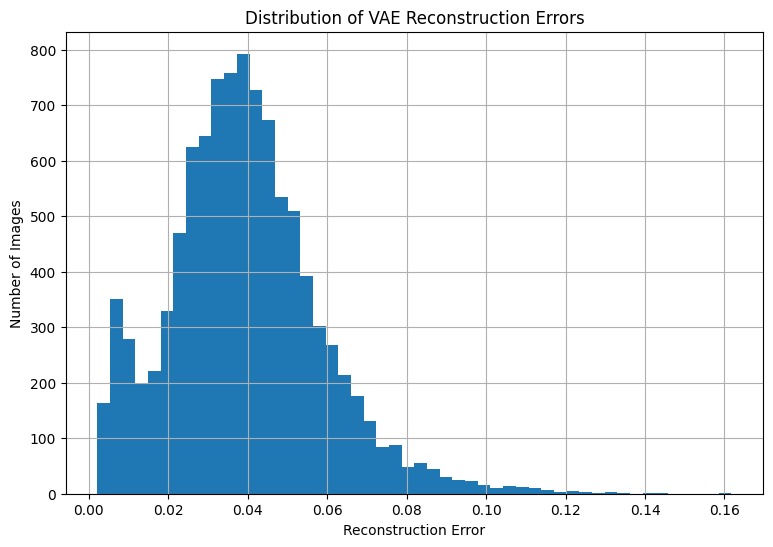

In [54]:
plt.figure(figsize=(9, 6))

plt.hist(
    vae_per_image_error,
    bins=50
)

plt.xlabel("Reconstruction Error")
plt.ylabel("Number of Images")
plt.title("Distribution of VAE Reconstruction Errors")
plt.grid()

save_fig("17_VAE_Reconstruction_Error_Distribution")
plt.show()

Top 5 high-error image indices:
1. Index = 2462, Error = 0.161758
2. Index = 2326, Error = 0.145169
3. Index = 3727, Error = 0.140375
4. Index = 7871, Error = 0.135632
5. Index = 8, Error = 0.135311


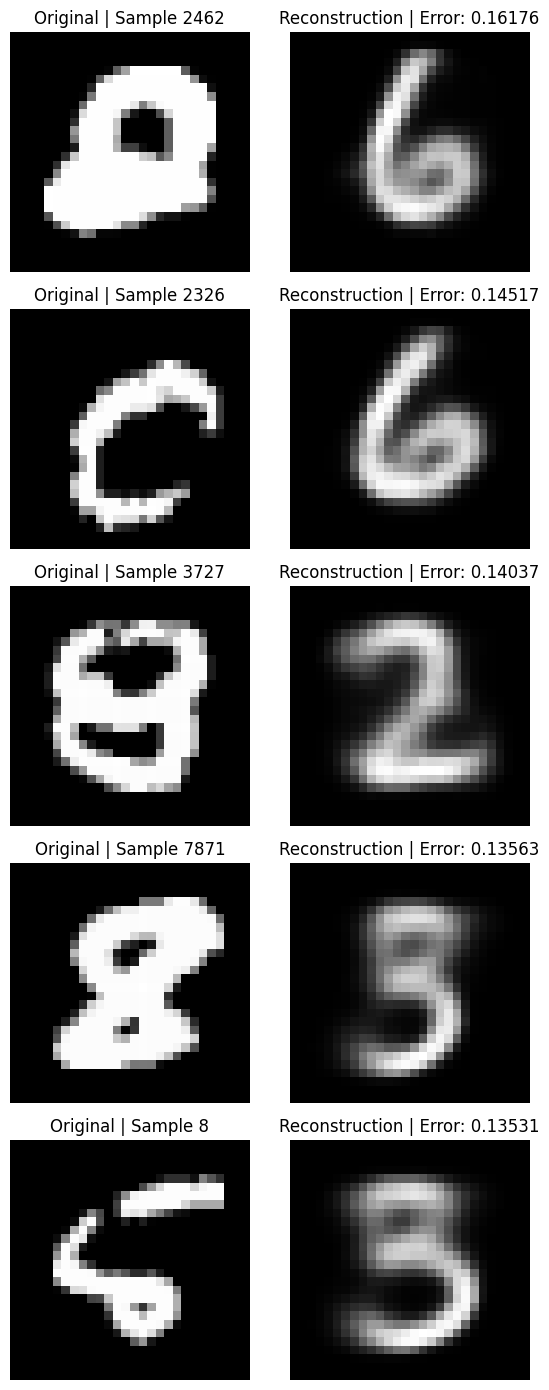

In [55]:
top_5_indices = np.argsort(
    vae_per_image_error
)[-5:][::-1]

print("Top 5 high-error image indices:")

for rank, index in enumerate(top_5_indices, start=1):
    print(
        f"{rank}. Index = {index}, "
        f"Error = {vae_per_image_error[index]:.6f}"
    )


fig, axes = plt.subplots(
    5,
    2,
    figsize=(6, 14)
)

for row, index in enumerate(top_5_indices):

    axes[row, 0].imshow(
        x_test[index].squeeze(),
        cmap="gray"
    )

    axes[row, 0].set_title(
        f"Original | Sample {index}"
    )

    axes[row, 0].axis("off")

    axes[row, 1].imshow(
        vae_reconstructed[index].squeeze(),
        cmap="gray"
    )

    axes[row, 1].set_title(
        f"Reconstruction | Error: {vae_per_image_error[index]:.5f}"
    )

    axes[row, 1].axis("off")

plt.tight_layout()
save_figure(fig, "18_Top_5_High_Error_VAE_Reconstructions")
plt.show()

In [56]:
high_error_table = pd.DataFrame({
    "Sample": range(1, 6),
    "Test Index": top_5_indices,
    "Reconstruction Error": [
        vae_per_image_error[i]
        for i in top_5_indices
    ]
})

high_error_table["Digit"] = [
    y_test[i]
    for i in top_5_indices
]

high_error_table

,Sample,Test Index,Reconstruction Error,Digit
0,1,2462,0.161758,2
1,2,2326,0.145169,0
2,3,3727,0.140375,8
3,4,7871,0.135632,8
4,5,8,0.135311,5


In [57]:
import time

def calculate_metrics(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    mse = mean_squared_error(
        y_true.reshape(len(y_true), -1),
        y_pred.reshape(len(y_pred), -1)
    )

    mae = mean_absolute_error(
        y_true.reshape(len(y_true), -1),
        y_pred.reshape(len(y_pred), -1)
    )

    ssim_scores = []

    for i in range(len(y_true)):
        score = ssim(
            y_true[i].squeeze(),
            y_pred[i].squeeze(),
            data_range=1.0
        )
        ssim_scores.append(score)

    return mse, mae, np.mean(ssim_scores)


x_test_images = np.asarray(x_test).astype("float32")
x_test_flat = x_test_images.reshape(
    x_test_images.shape[0],
    -1
)

results = []


# FC Autoencoder
start = time.perf_counter()

fc_reconstructed = fc_autoencoder.predict(
    x_test_flat,
    verbose=0
)

fc_time = time.perf_counter() - start

fc_reconstructed = np.asarray(
    fc_reconstructed
).reshape(x_test_images.shape)

fc_mse, fc_mae, fc_ssim = calculate_metrics(
    x_test_images,
    fc_reconstructed
)

fc_parameters = fc_autoencoder.count_params()

results.append([
    "FC Autoencoder",
    fc_mse,
    fc_mae,
    fc_ssim,
    fc_parameters,
    fc_time
])


# Convolutional Autoencoder
start = time.perf_counter()

conv_reconstructed = conv_autoencoder.predict(
    x_test_images,
    verbose=0
)

conv_time = time.perf_counter() - start

conv_reconstructed = np.asarray(
    conv_reconstructed
)

conv_mse, conv_mae, conv_ssim = calculate_metrics(
    x_test_images,
    conv_reconstructed
)

conv_parameters = conv_autoencoder.count_params()

results.append([
    "Conv. Autoencoder",
    conv_mse,
    conv_mae,
    conv_ssim,
    conv_parameters,
    conv_time
])


# Denoising CAE
denoising_input = add_gaussian_noise(
    x_test_images,
    0.2
)

start = time.perf_counter()

denoised_reconstructed = denoising_autoencoder.predict(
    denoising_input,
    verbose=0
)

denoising_time = time.perf_counter() - start

denoised_reconstructed = np.asarray(
    denoised_reconstructed
)

denoising_mse, denoising_mae, denoising_ssim = calculate_metrics(
    x_test_images,
    denoised_reconstructed
)

denoising_parameters = denoising_autoencoder.count_params()

results.append([
    "Denoising CAE",
    denoising_mse,
    denoising_mae,
    denoising_ssim,
    denoising_parameters,
    denoising_time
])


# VAE
start = time.perf_counter()

vae_mu, vae_log_var, vae_z = encoder(
    x_test_images,
    training=False
)

vae_reconstructed = decoder(
    vae_z,
    training=False
).numpy()

vae_time = time.perf_counter() - start

vae_mse, vae_mae, vae_ssim = calculate_metrics(
    x_test_images,
    vae_reconstructed
)

vae_parameters = vae.count_params()

results.append([
    "VAE",
    vae_mse,
    vae_mae,
    vae_ssim,
    vae_parameters,
    vae_time
])


# Final consolidated table
consolidated_results = pd.DataFrame(
    results,
    columns=[
        "Model",
        "MSE",
        "MAE",
        "SSIM",
        "Parameters",
        "Time (s)"
    ]
)

consolidated_results["MSE"] = (
    consolidated_results["MSE"].round(6)
)

consolidated_results["MAE"] = (
    consolidated_results["MAE"].round(6)
)

consolidated_results["SSIM"] = (
    consolidated_results["SSIM"].round(6)
)

consolidated_results["Time (s)"] = (
    consolidated_results["Time (s)"].round(4)
)

consolidated_results

,Model,MSE,MAE,SSIM,Parameters,Time (s)
0,FC Autoencoder,0.014010,0.042117,0.843624,211040,0.7576
1,Conv. Autoencoder,0.001133,0.010079,0.988807,74497,0.8233
2,Denoising CAE,0.003013,0.016950,0.962442,74497,1.3554
3,VAE,0.039306,0.093929,0.560105,133381,0.3529


In [58]:
latent_dimensions = [2, 8, 16, 32]

x_train_flat = x_train.reshape(
    x_train.shape[0],
    -1
)

x_val_flat = x_val.reshape(
    x_val.shape[0],
    -1
)

x_test_flat = x_test.reshape(
    x_test.shape[0],
    -1
)


def build_fc_autoencoder(latent_dim):

    inputs = layers.Input(
        shape=(784,)
    )

    x = layers.Dense(
        128,
        activation="relu"
    )(inputs)

    x = layers.Dense(
        64,
        activation="relu"
    )(x)

    latent = layers.Dense(
        latent_dim,
        activation="relu",
        name="latent"
    )(x)

    x = layers.Dense(
        64,
        activation="relu"
    )(latent)

    x = layers.Dense(
        128,
        activation="relu"
    )(x)

    outputs = layers.Dense(
        784,
        activation="sigmoid"
    )(x)

    return Model(
        inputs,
        outputs
    )


latent_results = []

for latent_dim in latent_dimensions:

    model = build_fc_autoencoder(
        latent_dim
    )

    model.compile(
        optimizer="adam",
        loss="mse"
    )

    model.fit(
        x_train_flat,
        x_train_flat,
        validation_data=(
            x_val_flat,
            x_val_flat
        ),
        epochs=20,
        batch_size=128,
        verbose=0
    )

    reconstructed = model.predict(
        x_test_flat,
        verbose=0
    )

    mse = mean_squared_error(
        x_test_flat,
        reconstructed
    )

    reconstructed_images = reconstructed.reshape(
        x_test.shape
    )

    ssim_scores = []

    for i in range(len(x_test)):

        score = ssim(
            x_test[i].squeeze(),
            reconstructed_images[i].squeeze(),
            data_range=1.0
        )

        ssim_scores.append(score)

    mean_ssim = np.mean(
        ssim_scores
    )

    parameters = model.count_params()

    latent_results.append([
        latent_dim,
        mse,
        mean_ssim,
        parameters
    ])


latent_results_df = pd.DataFrame(
    latent_results,
    columns=[
        "Latent Dimension",
        "MSE",
        "SSIM",
        "Parameters"
    ]
)

latent_results_df["MSE"] = (
    latent_results_df["MSE"].round(6)
)

latent_results_df["SSIM"] = (
    latent_results_df["SSIM"].round(6)
)

latent_results_df

,Latent Dimension,MSE,SSIM,Parameters
0,2,0.040465,0.545584,218514
1,8,0.019565,0.783788,219288
2,16,0.014794,0.832589,220320
3,32,0.008209,0.905917,222384


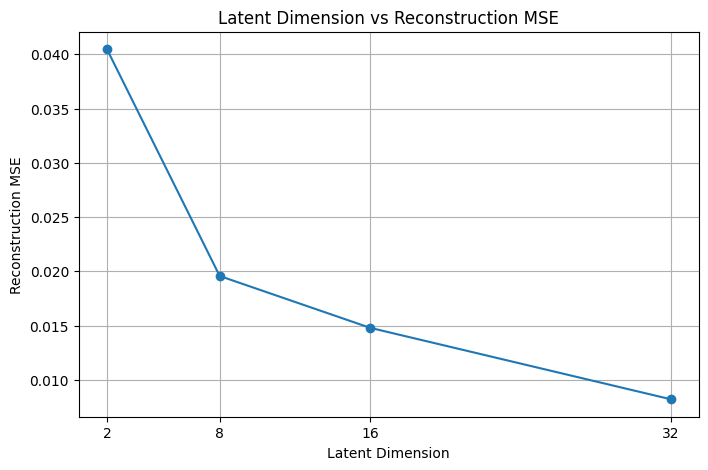

In [59]:
plt.figure(figsize=(8, 5))

plt.plot(
    latent_results_df["Latent Dimension"],
    latent_results_df["MSE"],
    marker="o"
)

plt.xlabel("Latent Dimension")
plt.ylabel("Reconstruction MSE")
plt.title("Latent Dimension vs Reconstruction MSE")
plt.xticks(latent_dimensions)
plt.grid()

save_fig("19_FC_AE_Latent_Dimension_vs_MSE")
plt.show()

In [60]:
def build_conv_ae(latent_dim):

    inputs = layers.Input(shape=(28, 28, 1))

    x = layers.Conv2D(
        32, 3, activation="relu", padding="same"
    )(inputs)

    x = layers.MaxPooling2D(2, padding="same")(x)

    x = layers.Conv2D(
        64, 3, activation="relu", padding="same"
    )(x)

    x = layers.MaxPooling2D(2, padding="same")(x)

    x = layers.Flatten()(x)

    latent = layers.Dense(
        latent_dim,
        activation="relu"
    )(x)

    x = layers.Dense(
        7 * 7 * 64,
        activation="relu"
    )(latent)

    x = layers.Reshape((7, 7, 64))(x)

    x = layers.UpSampling2D(2)(x)

    x = layers.Conv2D(
        32, 3, activation="relu", padding="same"
    )(x)

    x = layers.UpSampling2D(2)(x)

    outputs = layers.Conv2D(
        1, 3, activation="sigmoid", padding="same"
    )(x)

    return Model(inputs, outputs)


def calculate_ssim_batch(y_true, y_pred):

    scores = []

    for i in range(len(y_true)):

        scores.append(
            ssim(
                y_true[i].squeeze(),
                y_pred[i].squeeze(),
                data_range=1.0
            )
        )

    return np.mean(scores)


conv_latent_results = []

for latent_dim in [4, 8, 16, 32]:

    model = build_conv_ae(latent_dim)

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy"
    )

    model.fit(
        x_train,
        x_train,
        validation_data=(x_test, x_test),
        epochs=20,
        batch_size=128,
        verbose=0
    )

    reconstruction = model.predict(
        x_test,
        verbose=0
    )

    mse = mean_squared_error(
        x_test.reshape(len(x_test), -1),
        reconstruction.reshape(len(reconstruction), -1)
    )

    mean_ssim = calculate_ssim_batch(
        x_test,
        reconstruction
    )

    parameters = model.count_params()

    conv_latent_results.append([
        latent_dim,
        mse,
        mean_ssim,
        parameters
    ])


conv_latent_results_df = pd.DataFrame(
    conv_latent_results,
    columns=[
        "Latent Dimension",
        "MSE",
        "SSIM",
        "Parameters"
    ]
)

conv_latent_results_df

,Latent Dimension,MSE,SSIM,Parameters
0,4,0.038665,0.578751,65797
1,8,0.052944,0.385760,90889
2,16,0.022385,0.750616,141073
3,32,0.005710,0.938906,241441


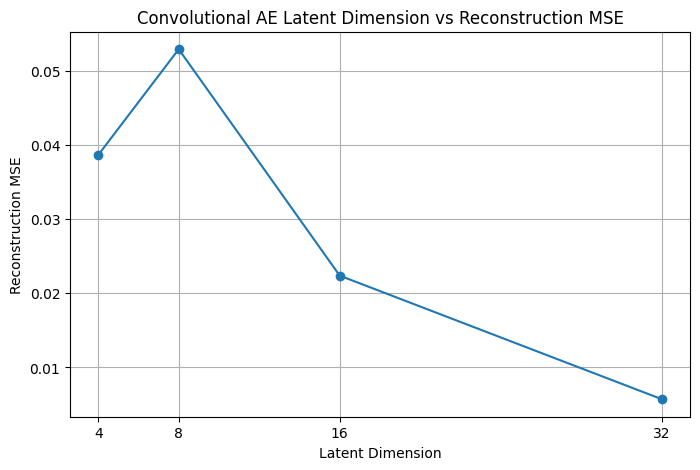

In [61]:

plt.figure(figsize=(8, 5))

plt.plot(
    conv_latent_results_df["Latent Dimension"],
    conv_latent_results_df["MSE"],
    marker="o"
)

plt.xlabel("Latent Dimension")
plt.ylabel("Reconstruction MSE")
plt.title("Convolutional AE Latent Dimension vs Reconstruction MSE")
plt.xticks([4, 8, 16, 32])
plt.grid()

save_fig("20_AE_Convolutional_Latent_Dimension_Comparison")
plt.show()


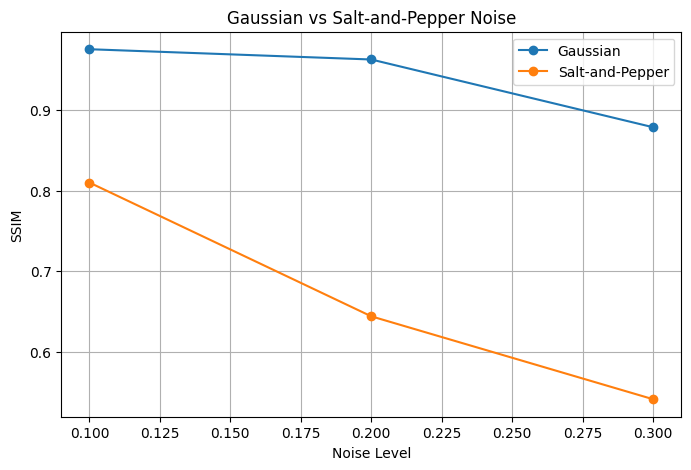

In [62]:
def add_salt_pepper_noise(images, amount):

    noisy = images.copy()

    random_values = np.random.rand(*images.shape)

    noisy[random_values < amount / 2] = 0
    noisy[random_values > 1 - amount / 2] = 1

    return noisy

noise_levels = [0.1, 0.2, 0.3]

noise_comparison = []

for level in noise_levels:

    gaussian_input = add_gaussian_noise(
        x_test,
        level
    )

    gaussian_output = denoising_autoencoder.predict(
        gaussian_input,
        verbose=0
    )

    gaussian_ssim = calculate_ssim_batch(
        x_test,
        gaussian_output
    )

    salt_pepper_input = add_salt_pepper_noise(
        x_test,
        level
    )

    salt_pepper_output = denoising_autoencoder.predict(
        salt_pepper_input,
        verbose=0
    )

    salt_pepper_ssim = calculate_ssim_batch(
        x_test,
        salt_pepper_output
    )

    noise_comparison.append([
        level,
        gaussian_ssim,
        salt_pepper_ssim
    ])


noise_comparison_df = pd.DataFrame(
    noise_comparison,
    columns=[
        "Noise Level",
        "Gaussian SSIM",
        "Salt-Pepper SSIM"
    ]
)

noise_comparison_df


plt.figure(figsize=(8, 5))

plt.plot(
    noise_comparison_df["Noise Level"],
    noise_comparison_df["Gaussian SSIM"],
    marker="o",
    label="Gaussian"
)

plt.plot(
    noise_comparison_df["Noise Level"],
    noise_comparison_df["Salt-Pepper SSIM"],
    marker="o",
    label="Salt-and-Pepper"
)

plt.xlabel("Noise Level")
plt.ylabel("SSIM")
plt.title("Gaussian vs Salt-and-Pepper Noise")
plt.legend()
plt.grid()

save_fig("22_AE_Gaussian_vs_SaltPepper_SSIM")
plt.show()

In [63]:
selected_noise_levels = [0.1, 0.3]

two_level_results = []

for sigma in selected_noise_levels:

    noisy = add_gaussian_noise(
        x_test,
        sigma
    )

    denoised = denoising_autoencoder.predict(
        noisy,
        verbose=0
    )

    ssim_value = calculate_ssim_batch(
        x_test,
        denoised
    )

    two_level_results.append([
        sigma,
        ssim_value
    ])


two_level_results_df = pd.DataFrame(
    two_level_results,
    columns=[
        "Noise Level",
        "SSIM"
    ]
)

two_level_results_df

,Noise Level,SSIM
0,0.1,0.975121
1,0.3,0.879561


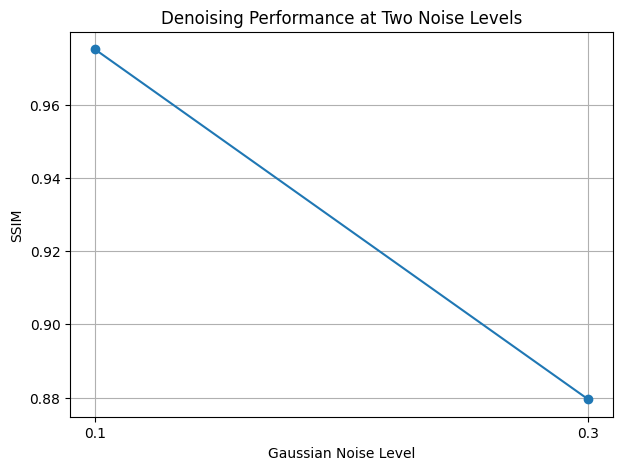

In [64]:

plt.figure(figsize=(7, 5))

plt.plot(
    two_level_results_df["Noise Level"],
    two_level_results_df["SSIM"],
    marker="o"
)

plt.xlabel("Gaussian Noise Level")
plt.ylabel("SSIM")
plt.title("Denoising Performance at Two Noise Levels")
plt.xticks(selected_noise_levels)
plt.grid()

save_fig("21_AE_Two_Noise_Levels_SSIM")
plt.show()


In [65]:
def build_transpose_conv_ae(latent_dim=16):

    inputs = layers.Input(
        shape=(28, 28, 1)
    )

    x = layers.Conv2D(
        32,
        3,
        activation="relu",
        padding="same"
    )(inputs)

    x = layers.MaxPooling2D(
        2,
        padding="same"
    )(x)

    x = layers.Conv2D(
        64,
        3,
        activation="relu",
        padding="same"
    )(x)

    x = layers.MaxPooling2D(
        2,
        padding="same"
    )(x)

    x = layers.Flatten()(x)

    latent = layers.Dense(
        latent_dim,
        activation="relu"
    )(x)

    x = layers.Dense(
        7 * 7 * 64,
        activation="relu"
    )(latent)

    x = layers.Reshape(
        (7, 7, 64)
    )(x)

    x = layers.Conv2DTranspose(
        64,
        3,
        strides=2,
        padding="same",
        activation="relu"
    )(x)

    x = layers.Conv2DTranspose(
        32,
        3,
        strides=2,
        padding="same",
        activation="relu"
    )(x)

    outputs = layers.Conv2D(
        1,
        3,
        padding="same",
        activation="sigmoid"
    )(x)

    return Model(
        inputs,
        outputs
    )


transpose_ae = build_transpose_conv_ae(
    latent_dim=16
)

transpose_ae.compile(
    optimizer="adam",
    loss="binary_crossentropy"
)

transpose_history = transpose_ae.fit(
    x_train,
    x_train,
    validation_data=(x_test, x_test),
    epochs=20,
    batch_size=128,
    verbose=0
)

transpose_reconstruction = transpose_ae.predict(
    x_test,
    verbose=0
)

transpose_mse = mean_squared_error(
    x_test.reshape(len(x_test), -1),
    transpose_reconstruction.reshape(
        len(transpose_reconstruction), -1
    )
)

transpose_ssim = calculate_ssim_batch(
    x_test,
    transpose_reconstruction
)

print("MSE:", transpose_mse)
print("SSIM:", transpose_ssim)
print("Parameters:", transpose_ae.count_params())

MSE: 0.02505214512348175
SSIM: 0.7307321354980509
Parameters: 178001


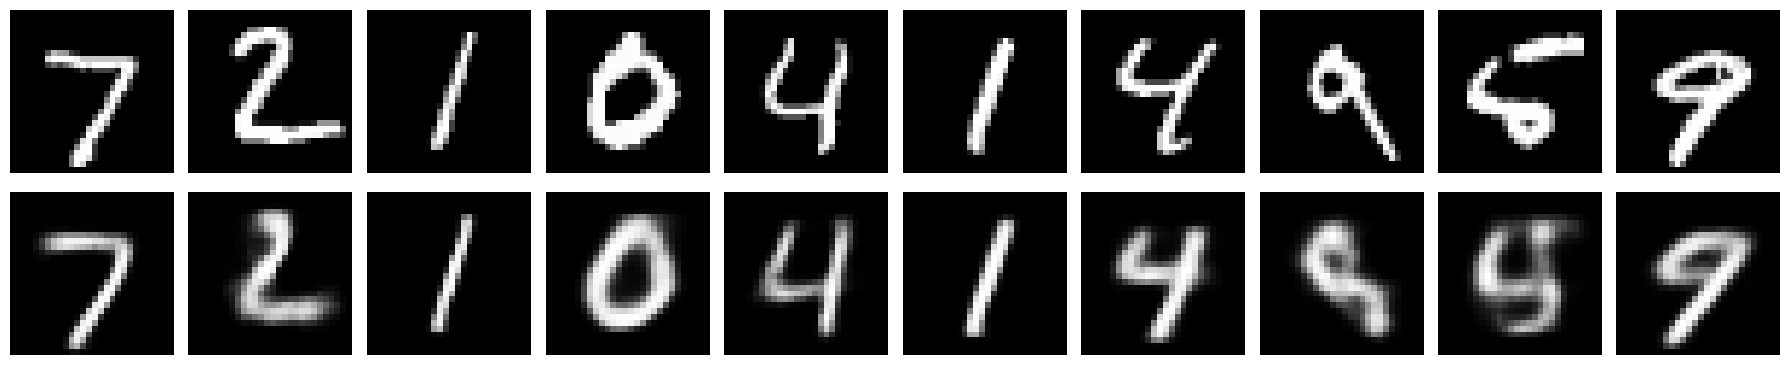

In [66]:

n = 10

fig, axes = plt.subplots(
    2,
    n,
    figsize=(18, 4)
)

for i in range(n):

    axes[0, i].imshow(
        x_test[i].squeeze(),
        cmap="gray"
    )
    axes[0, i].axis("off")

    axes[1, i].imshow(
        transpose_reconstruction[i].squeeze(),
        cmap="gray"
    )
    axes[1, i].axis("off")

axes[0, 0].set_ylabel(
    "Original",
    fontsize=12
)

axes[1, 0].set_ylabel(
    "Transpose Conv",
    fontsize=12
)

plt.tight_layout()

save_figure(
    fig,
    "23_AE_Transpose_Convolution_Reconstruction"
)

plt.show()


In [67]:
def build_vae(latent_dim):

    inputs = layers.Input(
        shape=(28, 28, 1)
    )

    x = layers.Conv2D(
        32,
        3,
        activation="relu",
        strides=2,
        padding="same"
    )(inputs)

    x = layers.Conv2D(
        64,
        3,
        activation="relu",
        strides=2,
        padding="same"
    )(x)

    x = layers.Flatten()(x)

    x = layers.Dense(
        128,
        activation="relu"
    )(x)

    mu = layers.Dense(
        latent_dim,
        name="mu"
    )(x)

    log_var = layers.Dense(
        latent_dim,
        name="log_var"
    )(x)

    def sampling(args):

        mu, log_var = args

        epsilon = tf.random.normal(
            shape=tf.shape(mu)
        )

        return mu + tf.exp(
            0.5 * log_var
        ) * epsilon

    z = layers.Lambda(
        sampling,
        name="z"
    )([mu, log_var])

    encoder = Model(
        inputs,
        [mu, log_var, z],
        name=f"encoder_{latent_dim}"
    )

    latent_inputs = layers.Input(
        shape=(latent_dim,)
    )

    x = layers.Dense(
        7 * 7 * 64,
        activation="relu"
    )(latent_inputs)

    x = layers.Reshape(
        (7, 7, 64)
    )(x)

    x = layers.Conv2DTranspose(
        64,
        3,
        strides=2,
        activation="relu",
        padding="same"
    )(x)

    x = layers.Conv2DTranspose(
        32,
        3,
        strides=2,
        activation="relu",
        padding="same"
    )(x)

    outputs = layers.Conv2D(
        1,
        3,
        activation="sigmoid",
        padding="same"
    )(x)

    decoder = Model(
        latent_inputs,
        outputs,
        name=f"decoder_{latent_dim}"
    )


    class VAE(Model):

        def __init__(
            self,
            encoder,
            decoder
        ):
            super().__init__()

            self.encoder = encoder
            self.decoder = decoder

        def call(
            self,
            inputs,
            training=False
        ):

            mu, log_var, z = self.encoder(
                inputs,
                training=training
            )

            reconstruction = self.decoder(
                z,
                training=training
            )

            return reconstruction

        def train_step(self, data):

            with tf.GradientTape() as tape:

                mu, log_var, z = self.encoder(
                    data,
                    training=True
                )

                reconstruction = self.decoder(
                    z,
                    training=True
                )

                reconstruction_loss = tf.reduce_mean(
                    tf.reduce_sum(
                        tf.keras.losses.binary_crossentropy(
                            data,
                            reconstruction
                        ),
                        axis=(1, 2)
                    )
                )

                kl_loss = -0.5 * tf.reduce_mean(
                    tf.reduce_sum(
                        1 + log_var
                        - tf.square(mu)
                        - tf.exp(log_var),
                        axis=1
                    )
                )

                total_loss = (
                    reconstruction_loss
                    + kl_loss
                )

            gradients = tape.gradient(
                total_loss,
                self.trainable_weights
            )

            self.optimizer.apply_gradients(
                zip(
                    gradients,
                    self.trainable_weights
                )
            )

            return {
                "loss": total_loss,
                "reconstruction_loss": reconstruction_loss,
                "kl_loss": kl_loss
            }

        def test_step(self, data):

            mu, log_var, z = self.encoder(
                data,
                training=False
            )

            reconstruction = self.decoder(
                z,
                training=False
            )

            reconstruction_loss = tf.reduce_mean(
                tf.reduce_sum(
                    tf.keras.losses.binary_crossentropy(
                        data,
                        reconstruction
                    ),
                    axis=(1, 2)
                )
            )

            kl_loss = -0.5 * tf.reduce_mean(
                tf.reduce_sum(
                    1 + log_var
                    - tf.square(mu)
                    - tf.exp(log_var),
                    axis=1
                )
            )

            total_loss = (
                reconstruction_loss
                + kl_loss
            )

            return {
                "loss": total_loss,
                "reconstruction_loss": reconstruction_loss,
                "kl_loss": kl_loss
            }


    vae = VAE(
        encoder,
        decoder
    )

    vae.compile(
        optimizer="adam"
    )

    return vae, encoder, decoder

Latent dimension 2: (10000, 2)
Latent dimension 8: (10000, 8)


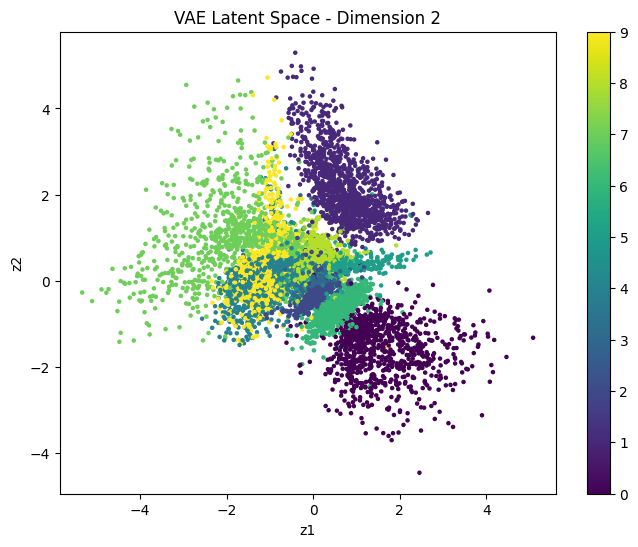

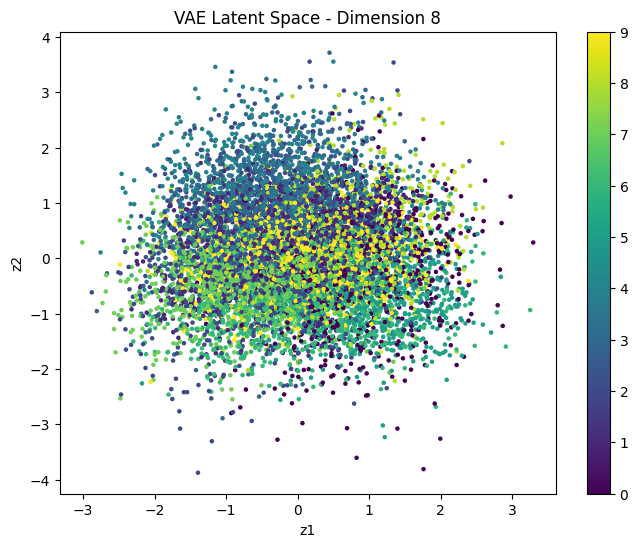

In [68]:
vae_2, encoder_2, decoder_2 = build_vae(2)

history_2 = vae_2.fit(
    x_train,
    epochs=20,
    batch_size=128,
    validation_data=(x_test,),
    verbose=0
)

vae_8, encoder_8, decoder_8 = build_vae(8)

history_8 = vae_8.fit(
    x_train,
    epochs=20,
    batch_size=128,
    validation_data=(x_test,),
    verbose=0
)

mu_2, log_var_2, z_2 = encoder_2.predict(
    x_test,
    verbose=0
)

mu_8, log_var_8, z_8 = encoder_8.predict(
    x_test,
    verbose=0
)

print("Latent dimension 2:", z_2.shape)
print("Latent dimension 8:", z_8.shape)


plt.figure(figsize=(8, 6))

plt.scatter(
    z_2[:, 0],
    z_2[:, 1],
    c=y_test,
    s=5
)

plt.xlabel("z1")
plt.ylabel("z2")
plt.title("VAE Latent Space - Dimension 2")
plt.colorbar()

save_fig("26_VAE_Latent_Dimension_2")
save_fig("27_VAE_Latent_Dimension_8")
plt.show()

plt.figure(figsize=(8, 6))

plt.scatter(
    z_8[:, 0],
    z_8[:, 1],
    c=y_test,
    s=5
)

plt.xlabel("z1")
plt.ylabel("z2")
plt.title("VAE Latent Space - Dimension 8")
plt.colorbar()

plt.show()

In [69]:
def build_beta_vae(latent_dim=2, beta=1.0):

    inputs = layers.Input(
        shape=(28, 28, 1)
    )

    x = layers.Conv2D(
        32,
        3,
        strides=2,
        padding="same",
        activation="relu"
    )(inputs)

    x = layers.Conv2D(
        64,
        3,
        strides=2,
        padding="same",
        activation="relu"
    )(x)

    x = layers.Flatten()(x)

    x = layers.Dense(
        128,
        activation="relu"
    )(x)

    mu = layers.Dense(
        latent_dim,
        name="mu"
    )(x)

    log_var = layers.Dense(
        latent_dim,
        name="log_var"
    )(x)

    def sampling(args):

        mu, log_var = args

        epsilon = tf.random.normal(
            shape=tf.shape(mu)
        )

        return (
            mu
            + tf.exp(0.5 * log_var) * epsilon
        )

    z = layers.Lambda(
        sampling,
        name="z"
    )([mu, log_var])

    encoder = Model(
        inputs,
        [mu, log_var, z],
        name=f"beta_encoder_{latent_dim}"
    )

    latent_input = layers.Input(
        shape=(latent_dim,)
    )

    x = layers.Dense(
        7 * 7 * 64,
        activation="relu"
    )(latent_input)

    x = layers.Reshape(
        (7, 7, 64)
    )(x)

    x = layers.Conv2DTranspose(
        64,
        3,
        strides=2,
        padding="same",
        activation="relu"
    )(x)

    x = layers.Conv2DTranspose(
        32,
        3,
        strides=2,
        padding="same",
        activation="relu"
    )(x)

    output = layers.Conv2D(
        1,
        3,
        padding="same",
        activation="sigmoid"
    )(x)

    decoder = Model(
        latent_input,
        output,
        name=f"beta_decoder_{latent_dim}"
    )


    class BetaVAE(Model):

        def __init__(
            self,
            encoder,
            decoder,
            beta
        ):
            super().__init__()

            self.encoder = encoder
            self.decoder = decoder
            self.beta = beta

        def call(
            self,
            inputs,
            training=False
        ):

            mu, log_var, z = self.encoder(
                inputs,
                training=training
            )

            reconstruction = self.decoder(
                z,
                training=training
            )

            return reconstruction

        def train_step(self, data):

            with tf.GradientTape() as tape:

                mu, log_var, z = self.encoder(
                    data,
                    training=True
                )

                reconstruction = self.decoder(
                    z,
                    training=True
                )

                reconstruction_loss = tf.reduce_mean(
                    tf.reduce_sum(
                        tf.keras.losses.binary_crossentropy(
                            data,
                            reconstruction
                        ),
                        axis=(1, 2)
                    )
                )

                kl_loss = -0.5 * tf.reduce_mean(
                    tf.reduce_sum(
                        1
                        + log_var
                        - tf.square(mu)
                        - tf.exp(log_var),
                        axis=1
                    )
                )

                total_loss = (
                    reconstruction_loss
                    + self.beta * kl_loss
                )

            gradients = tape.gradient(
                total_loss,
                self.trainable_weights
            )

            self.optimizer.apply_gradients(
                zip(
                    gradients,
                    self.trainable_weights
                )
            )

            return {
                "loss": total_loss,
                "reconstruction_loss": reconstruction_loss,
                "kl_loss": kl_loss
            }

        def test_step(self, data):

            mu, log_var, z = self.encoder(
                data,
                training=False
            )

            reconstruction = self.decoder(
                z,
                training=False
            )

            reconstruction_loss = tf.reduce_mean(
                tf.reduce_sum(
                    tf.keras.losses.binary_crossentropy(
                        data,
                        reconstruction
                    ),
                    axis=(1, 2)
                )
            )

            kl_loss = -0.5 * tf.reduce_mean(
                tf.reduce_sum(
                    1
                    + log_var
                    - tf.square(mu)
                    - tf.exp(log_var),
                    axis=1
                )
            )

            total_loss = (
                reconstruction_loss
                + self.beta * kl_loss
            )

            return {
                "loss": total_loss,
                "reconstruction_loss": reconstruction_loss,
                "kl_loss": kl_loss
            }


    vae = BetaVAE(
        encoder,
        decoder,
        beta
    )

    vae.compile(
        optimizer="adam"
    )

    return vae, encoder, decoder


beta_values = [
    0.1,
    1.0,
    2.0,
    5.0
]

beta_results = []

for beta in beta_values:

    print(f"Training β = {beta}")

    vae_beta, enc_beta, dec_beta = build_beta_vae(
        latent_dim=2,
        beta=beta
    )

    history_beta = vae_beta.fit(
        x_train,
        epochs=20,
        batch_size=128,
        validation_data=(x_test,),
        verbose=0
    )

    final_loss = history_beta.history[
        "loss"
    ][-1]

    final_reconstruction = history_beta.history[
        "reconstruction_loss"
    ][-1]

    final_kl = history_beta.history[
        "kl_loss"
    ][-1]

    beta_results.append([
        beta,
        final_reconstruction,
        final_kl,
        final_loss
    ])


beta_results_df = pd.DataFrame(
    beta_results,
    columns=[
        "Beta",
        "Reconstruction Loss",
        "KL Loss",
        "Total Loss"
    ]
)

beta_results_df

Training β = 0.1
Training β = 1.0
Training β = 2.0
Training β = 5.0


,Beta,Reconstruction Loss,KL Loss,Total Loss
0,0.1,139.263229,10.416072,140.304840
1,1.0,141.365387,6.490149,147.855530
2,2.0,142.547272,5.524297,153.595871
3,5.0,148.363602,4.163291,169.180054


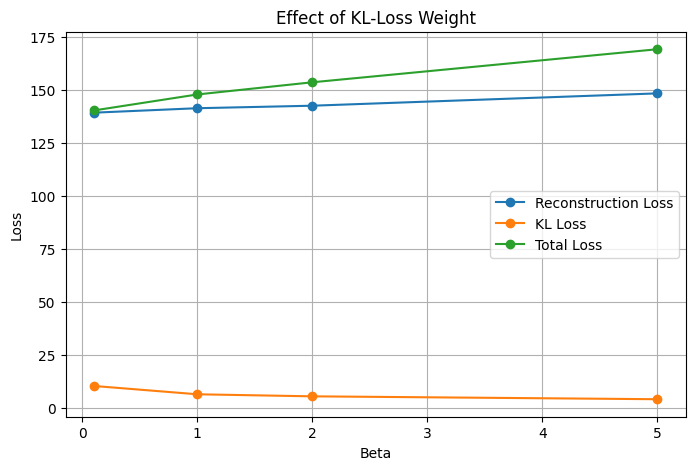

In [70]:

plt.figure(figsize=(8, 5))

plt.plot(
    beta_results_df["Beta"],
    beta_results_df["Reconstruction Loss"],
    marker="o",
    label="Reconstruction Loss"
)

plt.plot(
    beta_results_df["Beta"],
    beta_results_df["KL Loss"],
    marker="o",
    label="KL Loss"
)

plt.plot(
    beta_results_df["Beta"],
    beta_results_df["Total Loss"],
    marker="o",
    label="Total Loss"
)

plt.xlabel("Beta")
plt.ylabel("Loss")
plt.title("Effect of KL-Loss Weight")
plt.legend()
plt.grid()

save_fig("28_VAE_Beta_KL_Loss_Effect")
plt.show()


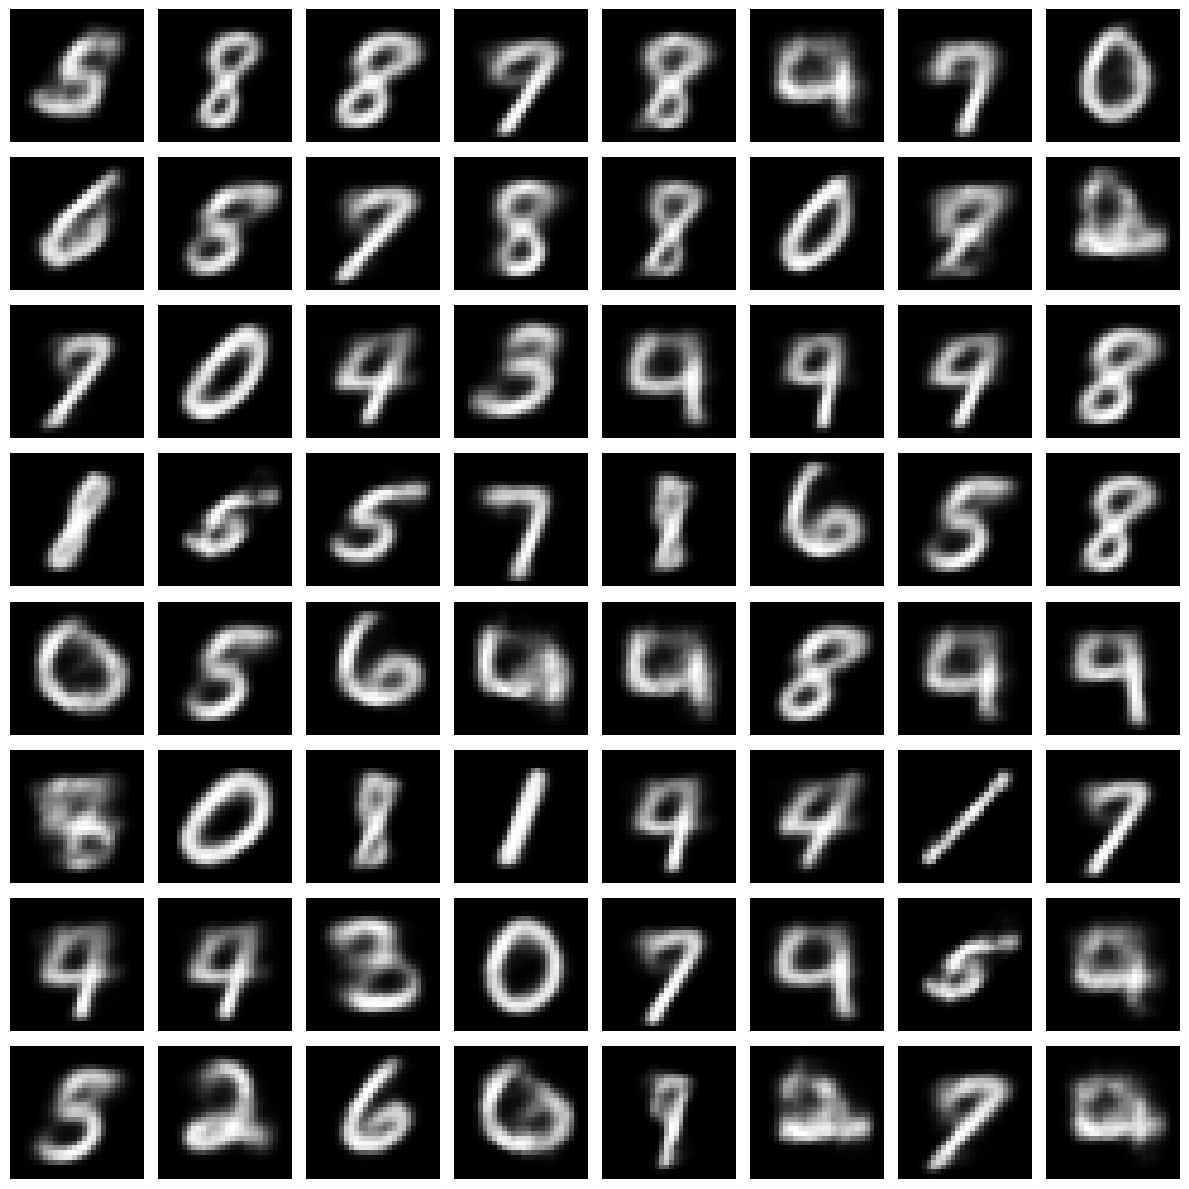

In [71]:
n_samples = 64

random_latents = np.random.normal(
    size=(n_samples, 2)
)

generated_images = decoder.predict(
    random_latents,
    verbose=0
)

fig, axes = plt.subplots(
    8,
    8,
    figsize=(12, 12)
)

for i, ax in enumerate(axes.flat):

    ax.imshow(
        generated_images[i].squeeze(),
        cmap="gray"
    )

    ax.axis("off")

plt.tight_layout()
save_figure(fig, "24_VAE_64_Sample_Grid")
plt.show()

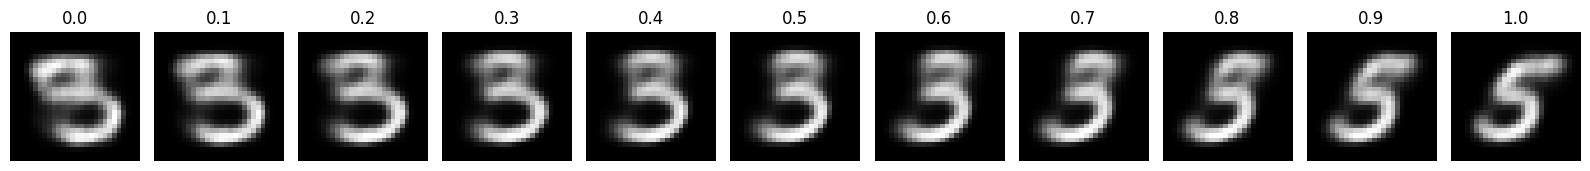

In [72]:
digit_a = 3
digit_b = 8

index_a = np.where(
    y_test == digit_a
)[0][0]

index_b = np.where(
    y_test == digit_b
)[0][0]

z_a = encoder.predict(
    x_test[index_a:index_a + 1],
    verbose=0
)[2][0]

z_b = encoder.predict(
    x_test[index_b:index_b + 1],
    verbose=0
)[2][0]

alphas = np.linspace(
    0,
    1,
    11
)

interpolated_z = np.array([
    (1 - alpha) * z_a + alpha * z_b
    for alpha in alphas
])

interpolated_images = decoder.predict(
    interpolated_z,
    verbose=0
)


plt.figure(figsize=(16, 3))

for i in range(11):

    plt.subplot(1, 11, i + 1)

    plt.imshow(
        interpolated_images[i].squeeze(),
        cmap="gray"
    )

    plt.axis("off")
    plt.title(
        f"{alphas[i]:.1f}"
    )

plt.tight_layout()
save_fig("25_VAE_Digit_3_to_8_Interpolation")
plt.show()